[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab5-Comp-Mod/Kiwi-challenge/notebooks/01-kiwi-growth-and-morphogenesis.ipynb)

# The Computational Kiwi Challenge (Part 1): From Genes & Hormones to 3D Morphogenesis

**BMED365 — Computational Imaging, Modeling and AI in Biomedicine (Lab 5, Spring 2027)**  
*Arvid Lundervold — runs locally with `uv` (`bmed365-2027` kernel) or in Google Colab*

> **Lab 4 (Imaging) $\leftrightarrow$ Lab 5 (Computational Modeling) "Digital Twin" Bridge:**
> - **In [Lab 4 (`Lab4-Comp-Imag/Kiwi-challenge`)](../../../Lab4-Comp-Imag/Kiwi-challenge/README.md):** We solved the *observational* problem — converting 128 Bruker 7T DICOM slices to NIfTI (`00`), exploring 3D voxel geometry (`01`), segmenting ~1,440 seeds (`02`–`04`), and auditing accuracy without dissecting the fruit (`03`, `03b`).
> - **In Lab 5 (`Lab5-Comp-Mod/Kiwi-challenge`):**
>   0. [`00-kiwi-math-primer-for-biomedicine.ipynb`](./00-kiwi-math-primer-for-biomedicine.ipynb) — **Visual Math Primer ("Rosetta Stone"):** Friendly, intuition-first visual guide to saturation/Hill curves, ODEs, $\nabla^2$ diffusion, Turing peaks, spatial point processes, Tikhonov regularization, and Rician MRI noise for biomedicine students & clinicians.
>   0a. [`00a-kiwi-anatomical-and-physiological-atlas.ipynb`](./00a-kiwi-anatomical-and-physiological-atlas.ipynb) — **Multi-Scale Anatomical & Physiological Atlas:** Macroscopic optical vs. 7T MRI contrast inversion, $\mu\text{m}$-scale histology, dioecious `XY` flowers, `BBCH` life cycle, & physiology.
>   1. **`01-kiwi-growth-and-morphogenesis.ipynb` (this notebook)** — A progressive, step-by-step modeling tutorial (**Algebraic Saturation $\to$ Bistable Gene & Biophysical ODEs $\to$ 1D Ring Turing & 2D Paracrine Diffusion PDEs**), tested directly against our **real 2005 7T MRI scan** with explicit parallels to **human physiology & pathology**.
>   2. [`02-kiwi-digital-twin-and-inverse-problems.ipynb`](./02-kiwi-digital-twin-and-inverse-problems.ipynb) — Advanced quantitative research topics (**Polyploid Turing Stability, 3D Spatial Point Processes, Ill-Posed PDE Inverse Problems & a Generative 3D Bloch-MRI Digital Twin**).

---

## 1. Motivation, Learning Outcomes & Biomedical Bridge

### 1.1 Why Model a Kiwifruit in a Graduate Biomedicine Course?

In **Lab 4**, we used our 2005 7 Tesla kiwifruit MRI scan as an intuitive, zero-jargon stand-in for a **human brain MRI containing focal lesions** (such as multiple sclerosis plaques or cerebral microbleeds). Now in **Lab 5 (Computational Modeling)**, we flip the scientific question around:

> **Instead of only *measuring* the finished 3D anatomy inside an MRI scanner, can we write down the mathematical laws of *how living tissue built that 3D organ* — from sex-determining genes and symmetry-breaking morphogens to turgor mechanics, carbohydrate osmosis, and $T_2$ spin-echo MRI contrast?**

Coupling **3D non-invasive imaging** with **mechanistic ODE/PDE models** is the foundation of modern **patient-specific Digital Twins** in biomedicine — for example, segmenting a patient's heart, kidney, or solid tumor from MRI and simulating biophysical equations to predict disease progression or treatment response. Crucially, multicellular plants and humans solve the same physical problems (cell-fate switches, fluid-pressure expansion, reaction–diffusion patterning, and paracrine trophic signaling) using **identical mathematical equations**.

### 1.2 Learning Outcomes (MSc & PhD Students in Biomedicine)

After working through this notebook, you should be able to:

- **Core Outcomes (All MSc & PhD Biomedicine Students):**
  1. **Climb the modeling ladder:** Explain when a biological question can be answered by a simple **algebraic formula** (steady-state organ size), when it requires **Ordinary Differential Equations (ODEs)** (time dynamics without space), and when it requires **Partial Differential Equations (PDEs)** (spatial symmetry breaking and local tissue gradients).
  2. **Translate across kingdoms:** Map the four core mechanisms of kiwifruit development directly onto **human physiology and pathology** — pharmacodynamic $E_{\max}$ receptor saturation, mammalian `SRY`/`SOX9` gonadal sex determination, Starling/cystic fluid-pressure mechanics, `BMP`/`SOX9` digit patterning, and tumor `VEGF` / wound growth-factor diffusion.
  3. **Connect tissue biophysics to MRI physics:** Explain *why* mature seeds appear jet-black while surrounding locular gel appears bright in a 7T $T_2$-weighted RARE scan (`TE = 63.9 ms`), and why an immature fruit scanned early in development would look dramatically different.
  4. **Distinguish developmental canalization from asymmetry:** Explain how receptor saturation and hormone diffusion buffer random biological noise to produce symmetric organs — and why hemispheric signaling failure breaks that symmetry.

- **Advanced Methodological Outcomes (PhD & Quantitative Research Track):**
  5. **Formulate & solve multi-scale models:** Specify state variables, physical units, initial/boundary conditions, and numerical solvers (`solve_ivp` Runge–Kutta for ODEs; unconditionally stable semi-implicit Fourier spectral stepping and 2D Green's operators for PDEs).
  6. **Critically audit models against 3D imaging data:** Test mechanistic predictions slice-by-slice and sector-by-sector on a real `256 × 256 × 128` NIfTI volume while identifying geometric confounders (such as seedless polar caps and central core ovality).

---

### 1.3 Botanical $\leftrightarrow$ Human Biomedical Glossary

Because most biomedicine students have not studied plant anatomy since introductory biology, the table below defines every botanical term used in this module alongside its **plain-language intuition** and **human biomedical counterpart**:

| Term | Plain-Language Intuition | Rigorous Biological Meaning | Human Biomedical Counterpart |
| :--- | :--- | :--- | :--- |
| **Anthesis (`0 DAA`)** | Day the flower opens & is pollinated (`t = 0`) | Onset of ovule fertilization; developmental time is measured in **Days After Anthesis (`DAA`, `0–160 d`)** | **Fertilization / Gestational Day 0** in embryology |
| **Pericarp** | Fleshy fruit wall (outer green flesh + inner seed ring) | Mature ovary wall derived from fused floral carpels, expanding via cell division then cell enlargement | **Organ parenchyma / myocardial or renal cortex wall** |
| **Locules (`~33` chambers)** | Bright radial "spokes" holding the seeds | Mucilage-filled radial carpel cavities arranged in a ring around the fruit's central axis | **Renal lobes, hepatic lobules, or mammary glandular acini** |
| **Columella** | Dense central core (white optically, **dark in $T_2$ MRI!**) | Stiff, cellulose/pectin-rich axial core supporting vascular bundles; flattened like a blade | **Fibrous mediastinum / dense collagenous stroma** (short $T_2$ in MRI) |
| **Dioecy (`XY` sex)** | Separate male and female individuals | Female vines (`XXXXXX`) bear fruit; male vines (`XXXXXY`) carry Y-linked *Shy Girl* (`SyGI`) suppressing ovary growth (*Akagi et al., 2018, 2019*) | **Mammalian `XX`/`XY` gonadal sex determination** (`SRY`/`SOX9` vs. `WNT4` / $\beta$-catenin) |
| **Parthenocarpy** | Baseline fruit growth with zero seeds ($N = 0$) | Small basal ovary expansion ($V_{\text{basal}}$) occurring without seed-derived hormone stimulation | **Basal constitutive receptor activity** ($E_0$ in pharmacology) |
| **Turgor Pressure ($P$)** | Positive internal water pressure inflating cells | Hydrostatic pressure ($0.5\text{--}1.2\text{ MPa}$) generated by intracellular osmotic solutes pulling water across the plasma membrane | **Capillary hydrostatic & oncotic Starling pressures**; **polycystic kidney (`ADPKD`) cyst pressure** |
| **Developmental Canalization** | Robustness of organ shape despite noisy inputs | *Waddington's (1942)* principle that developmental pathways buffer stochastic genetic/environmental jitter to yield a reproducible phenotype | **Homeostatic buffering & symmetric bilateral organogenesis** |

---

## 2. Bridge from Lab 4: Extracting Physical 3D Observables from the 2005 7T MRI

A computational model is only scientific if its predictions can be confronted with **real physical measurements** in consistent units ($\text{mm}$, $\text{mm}^2$, $\text{cm}^3$). Before writing our first model equation, let's load the **2005 7T Bruker Pharmascan NIfTI scan** (`256 × 256 × 128` voxels) and extract four empirical observables:

1. **Physical voxel dimensions:** From the NIfTI header zooms $(\Delta x, \Delta y, \Delta z) = (0.234375,\; 0.234375,\; 0.5000)\text{ mm}$, each voxel represents a physical volume $\Delta V = \Delta x \Delta y \Delta z = 0.02747\text{ mm}^3$ and in-plane pixel area $\Delta A = \Delta x \Delta y = 0.05493\text{ mm}^2$.
2. **Whole-fruit 3D volume $V_{\text{MRI}}$ and axial area profile $A_{\text{MRI}}(z)$:** Summing foreground fruit voxels on each transaxial slice $z \in \{0, \dots, 127\}$ gives the cross-sectional area $A_{\text{MRI}}(z) = N_{\text{fg}}(z)\cdot\Delta A$ and total volume $V_{\text{MRI}} = \sum_z A_{\text{MRI}}(z)\cdot\Delta z$.
3. **3D seed centroids $\{\mathbf{x}_i\}$:** Extracted via Lab 4's validated **Rung 2B** pipeline (anisotropic physical-millimeter 3D grey-closing + distance-transform marker watershed + intensity/volume filtering).
4. **Recall-calibrated total seed count ($\hat{N}_{\text{cal}} \approx 1{,}440$):** In Lab 4 ([`03-kiwi-paradigms-and-verification.ipynb`](../../../Lab4-Comp-Imag/Kiwi-challenge/notebooks/03-kiwi-paradigms-and-verification.ipynb)), scoring Rung 2B against the 98 curated seeds in `kiwi_micro_gt_roi.json` showed that closely packed double-row seeds cause ~25% under-counting (`Recall < Precision`), yielding a bias-corrected whole-fruit estimate $\hat{N}_{\text{cal}} = \hat{N}_{\text{raw}} \cdot \frac{\text{Precision}}{\text{Recall}} \approx 1{,}440$ seeds.

In [1]:
%matplotlib inline

import json
import pathlib
import subprocess
import sys
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import integrate, ndimage as ndi, signal, stats

for pkg_import, pip_name in [
    ("nibabel", "nibabel"),
    ("skimage", "scikit-image"),
    ("ipywidgets", "ipywidgets"),
]:
    try:
        __import__(pkg_import)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

import nibabel as nib
from skimage import filters, measure, segmentation
import ipywidgets as widgets
from IPython.display import display

np.random.seed(42)
plt.rcParams["figure.dpi"] = 115
plt.rcParams["axes.titlesize"] = 10.5

GITHUB_LAB4_RAW = "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/Lab4-Comp-Imag/Kiwi-challenge"


def resolve_lab4_kiwi_file(rel_path: str) -> pathlib.Path:
    '''Find a Kiwi data file in Lab4-Comp-Imag locally, or download it automatically in Google Colab.'''
    candidates = [
        pathlib.Path("../../../Lab4-Comp-Imag/Kiwi-challenge") / rel_path,
        pathlib.Path("../../Lab4-Comp-Imag/Kiwi-challenge") / rel_path,
        pathlib.Path("Lab4-Comp-Imag/Kiwi-challenge") / rel_path,
        pathlib.Path(rel_path),
    ]
    for cand in candidates:
        if cand.exists():
            return cand
    dst = pathlib.Path(rel_path)
    dst.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading {rel_path} from GitHub for Colab session...")
    urllib.request.urlretrieve(f"{GITHUB_LAB4_RAW}/{rel_path}", dst)
    return dst


nii_path = resolve_lab4_kiwi_file("data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz")
gt_json_path = resolve_lab4_kiwi_file("data/kiwi_micro_gt_roi.json")

img = nib.load(str(nii_path))
vol = img.get_fdata(dtype=np.float32)
spacing = tuple(float(s) for s in img.header.get_zooms()[:3])  # (0.234375, 0.234375, 0.5) mm
dx, dy, dz = spacing
vox_vol_mm3 = dx * dy * dz
pix_area_mm2 = dx * dy
micro_gt_meta = json.loads(gt_json_path.read_text(encoding="utf-8"))

# 1. Whole-fruit 3D foreground mask & normalized radial coordinate r / R(z)
vol_sm = ndi.gaussian_filter(vol, sigma=(1.2 / dx, 1.2 / dy, 1.2 / dz))
fg_raw = vol_sm > (filters.threshold_otsu(vol_sm[::2, ::2, ::2]) * 0.35)
fg_fill = np.zeros_like(fg_raw)
for z in range(vol.shape[2]):
    fg_fill[:, :, z] = ndi.binary_fill_holes(fg_raw[:, :, z])
fg_fill = ndi.binary_fill_holes(fg_fill)
lbl_fg, _ = ndi.label(fg_fill)
fruit_mask = lbl_fg == (1 + int(np.argmax(np.bincount(lbl_fg.ravel())[1:])))

r_norm = np.full(vol.shape, 1.5, dtype=np.float32)
ix, iy = np.indices(vol.shape[:2], dtype=np.float32)
cx_z = np.full(vol.shape[2], 128.0)
cy_z = np.full(vol.shape[2], 128.0)
for z in range(vol.shape[2]):
    m = fruit_mask[:, :, z]
    if m.sum() >= 50:
        cx_z[z], cy_z[z] = ndi.center_of_mass(m)
        r_eq = np.sqrt(m.sum() / np.pi)
        r_norm[:, :, z] = np.sqrt((ix - cx_z[z]) ** 2 + (iy - cy_z[z]) ** 2) / max(r_eq, 1.0)

# 2. Extract 3D seed centroids using Lab 4's Rung 2B physical-space watershed pipeline
def _ellipsoid(rx_mm: float, rz_mm: float) -> np.ndarray:
    rx, ry, rz = int(np.ceil(rx_mm / dx)), int(np.ceil(rx_mm / dy)), int(np.ceil(rz_mm / dz))
    xx, yy, zz = np.ogrid[-rx : rx + 1, -ry : ry + 1, -rz : rz + 1]
    return ((xx * dx / rx_mm) ** 2 + (yy * dy / rx_mm) ** 2 + (zz * dz / rz_mm) ** 2) <= 1.0

fruit_interior = fruit_mask & (r_norm <= 0.92)
v_den = ndi.gaussian_filter(vol, sigma=(0.20 / dx, 0.20 / dy, 0.25 / dz))
closed_3d = ndi.grey_closing(v_den, footprint=_ellipsoid(1.15, 1.50))
bright_env = ndi.gaussian_filter(closed_3d, sigma=(1.2 / dx, 1.2 / dy, 1.2 / dz))
rel_drop = (closed_3d - v_den) / (bright_env + 1000.0)
fg_seeds = (
    (rel_drop > 0.30)
    & (bright_env > np.percentile(bright_env[fruit_interior], 56))
    & (v_den < 0.48 * bright_env)
    & fruit_interior
)
dist_mm = ndi.distance_transform_edt(fg_seeds, sampling=spacing)
peak_field = ndi.gaussian_filter(dist_mm * (0.5 + rel_drop), sigma=(0.28 / dx, 0.28 / dy, 0.38 / dz))
loc_max = (peak_field == ndi.maximum_filter(peak_field, footprint=_ellipsoid(0.78, 1.05))) & fg_seeds & (dist_mm >= 0.22)
markers, _ = ndi.label(loc_max)
ws = segmentation.watershed(-peak_field, markers=markers, mask=fg_seeds)

seed_centroids_vox = np.array([
    p.centroid for p in measure.regionprops(ws, intensity_image=v_den)
    if (0.28 <= p.area * vox_vol_mm3 <= 4.8)
    and (p.intensity_min <= 0.37 * bright_env[int(round(p.centroid[0])), int(round(p.centroid[1])), int(round(p.centroid[2]))])
    and (p.extent >= 0.24)
])

mri_fruit_vol_cm3 = float(fruit_mask.sum() * vox_vol_mm3 / 1000.0)
z_occupied = np.where(fruit_mask.sum(axis=(0, 1)) > 200)[0]
mri_length_mm = float((z_occupied[-1] - z_occupied[0] + 1) * dz)
mri_eq_diam_mm = float(2.0 * np.sqrt(fruit_mask[:, :, 64].sum() * pix_area_mm2 / np.pi))
N_calibrated = 1440  # Bias-calibrated whole-fruit seed count from Lab 4 Notebook 03
seed_vol_fraction_pct = (N_calibrated * micro_gt_meta["median_seed_vol_mm3"] / 1000.0) / mri_fruit_vol_cm3 * 100.0

print(f"7T MRI Whole-Fruit Volume : {mri_fruit_vol_cm3:.2f} cm^3  (length = {mri_length_mm:.1f} mm, equatorial diameter = {mri_eq_diam_mm:.1f} mm)")
print(f"Segmented 3D Seed Blobs   : {len(seed_centroids_vox):,} raw Rung-2B centroids (~{N_calibrated:,} after Micro-GT recall calibration)")
print(f"Curated Micro-GT Sector   : {micro_gt_meta['n_seeds_in_roi']} seeds (median single-seed volume = {micro_gt_meta['median_seed_vol_mm3']} mm^3)")
print(f"Total Seed Volume Fraction: ~{seed_vol_fraction_pct:.2f}% of whole-fruit volume")

7T MRI Whole-Fruit Volume : 85.97 cm^3  (length = 52.5 mm, equatorial diameter = 52.0 mm)
Segmented 3D Seed Blobs   : 1,075 raw Rung-2B centroids (~1,440 after Micro-GT recall calibration)
Curated Micro-GT Sector   : 98 seeds (median single-seed volume = 1.524 mm^3)
Total Seed Volume Fraction: ~2.55% of whole-fruit volume


### Interpreting the Baseline 3D MRI Measurements

Look closely at that fourth line of output:
- Our intact 2005 `'Hayward'` kiwifruit has a 3D volume of **`85.97 cm³`** (corresponding to `~90 g` fresh weight at tissue density $\rho \approx 1.04\text{ g/cm}^3$ — a classic commercial Grade-A fruit), spanning **`52.5 mm`** axially and **`52.0 mm`** across the equator.
- Yet all **`~1,440` seeds combined** (`1,440 × 1.524 mm³ ≈ 2.19 cm³`) physically occupy **only `~2.55%` of the fruit's volume**!
- **Why does `2.5%` of the volume control the size of the other `97.5%`?** Because fertilized seeds act as **endocrine/paracrine signaling hubs** — synthesizing auxin (`IAA`), cytokinins, and gibberellins that instruct the surrounding maternal pericarp parenchyma to divide, import phloem sugars, and expand. Let's model that signaling law first!

---

## 3. Stage 1 (Algebraic, Zero Calculus): Receptor Saturation & Axial MRI Allometry

### 3.1 Intuitive Picture: "Musical Chairs" on Pericarp Hormone Receptors
Orchard experiments (*Hopping, 1976*; *Pyke & Alspach, 1986*) established that poorly pollinated kiwifruit flowers (`< 100` seeds) abort or produce tiny `20–30 cm³` fruits, whereas `1,000–1,400` seeds yield `80–95 cm³` fruits — **with strong diminishing returns above ~1,000 seeds**.

*Intuitively*, why does adding 200 extra seeds matter hugely when $N = 100$, but barely move the needle when $N = 1{,}200$? Think of hormone molecules playing **musical chairs** with a finite number of receptor proteins on pericarp cells: when almost all receptors are empty, every new seed activates more growth; once `>75%` of receptors are already occupied, extra hormone ligands have few free receptors left to bind.

### 3.2 Rigorous Derivation & Parameter Table
Let $R_{\text{tot}}$ denote the concentration of pericarp hormone receptors and $[L] = \alpha N$ the steady-state ligand concentration secreted by $N$ fertilized seeds. At reversible binding equilibrium $R + L \underset{k_{\text{off}}}{\overset{k_{\text{on}}}{\rightleftharpoons}} RL$ with dissociation constant $K_d = k_{\text{off}} / k_{\text{on}}$, fractional receptor occupancy follows the **Michaelis–Menten / Hill ($n=1$) isotherm**:

$$\theta_{\text{occ}}(N) = \frac{[RL]}{R_{\text{tot}}} = \frac{[L]}{K_d + [L]} = \frac{N}{K_N + N}, \qquad K_N \equiv \frac{K_d}{\alpha}$$

Assuming mature pericarp expansion above the unpollinated parthenocarpic baseline $V_{\text{basal}}$ is proportional to receptor occupancy gives the **algebraic organ-scaling law**:

$$V_{\text{fruit}}(N) = V_{\text{basal}} + V_{\max}\,\frac{N}{K_N + N}, \qquad \frac{dV_{\text{fruit}}}{dN} = \frac{V_{\max}\,K_N}{(K_N + N)^2}$$

| Symbol | Value (`'Hayward'`) | Units | Physical / Biological Interpretation | Human Biomedical Analog |
| :--- | :--- | :--- | :--- | :--- |
| $N$ | $0 \dots 2{,}000$ | $\text{seeds}$ | Total fertilized, hormone-secreting seeds | Drug dose $D$ or functional **nephron count** |
| $V_{\text{basal}}$ | $18.0$ | $\text{cm}^3$ | Baseline parthenocarpic ovary volume at $N=0$ | Basal physiological response $E_0$ |
| $V_{\max}$ | $88.0$ | $\text{cm}^3$ | Maximal hormone-inducible pericarp volume gain | Maximal pharmacodynamic efficacy $E_{\max}$ |
| $K_N$ | $420$ | $\text{seeds}$ | Half-saturation seed count ($V(K_N) = V_{\text{basal}} + \frac{1}{2}V_{\max}$) | Potency $\text{EC}_{50}$ / dissociation constant $K_d$ |

Stage 1 Whole-Fruit Prediction at N = 1440 seeds : 86.13 cm^3  (Measured 7T MRI = 85.97 cm^3)
Estimated Pericarp Receptor Occupancy at N = 1,440        : 77.4% saturated
Axial Correlation A_MRI(z) vs Seed Density (all interior) : r = 0.851 (p = 5.84e-30, n = 103 slices)
Axial Correlation Restricted to Seed-Bearing Core         : r = 0.944 (p = 4.79e-34, n = 69 slices)


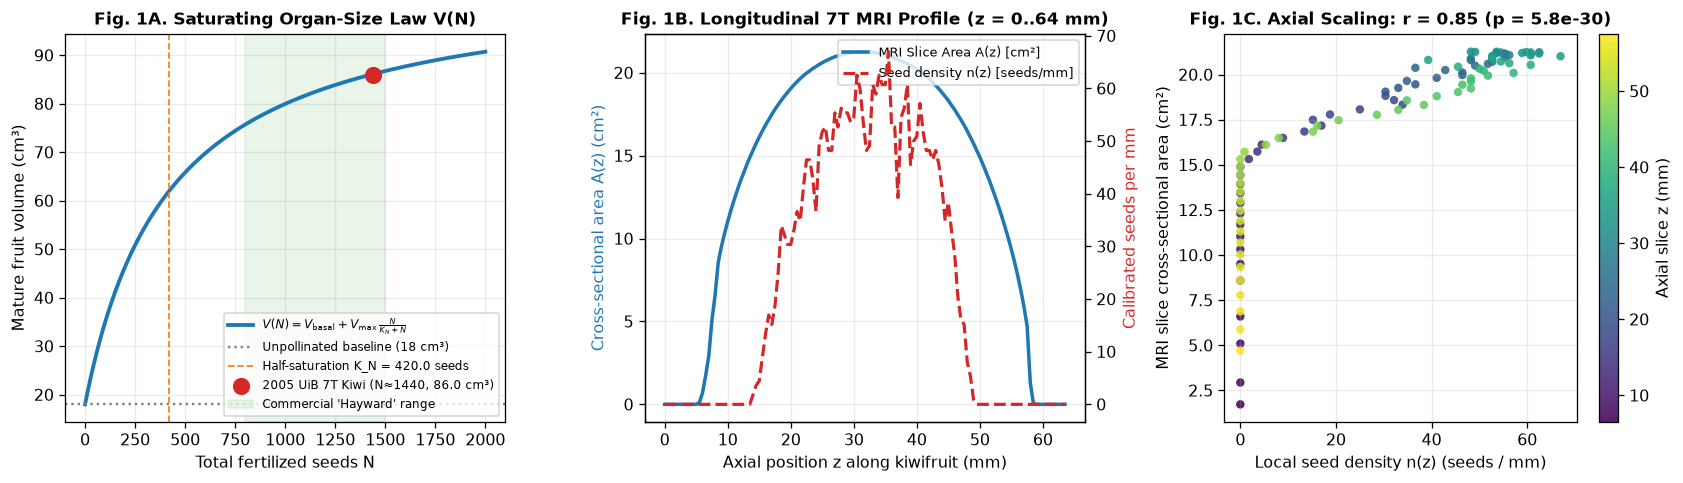

In [2]:
# 1. Whole-fruit Michaelis-Menten seed-to-volume curve (parameterized from Pyke & Alspach 1986 'Hayward' data)
V_basal, V_max, K_N = 18.0, 88.0, 420.0
N_grid = np.linspace(0, 2000, 400)
V_pred_curve = V_basal + V_max * (N_grid / (K_N + N_grid))
V_pred_our_kiwi = V_basal + V_max * (N_calibrated / (K_N + N_calibrated))
occ_our_kiwi = N_calibrated / (K_N + N_calibrated) * 100.0

# 2. Slice-by-slice cross-sectional area A_MRI(z) vs local seed density n_seeds(z)
z_idx = np.arange(vol.shape[2])
z_mm = z_idx * dz
slice_area_mm2 = fruit_mask.sum(axis=(0, 1)) * pix_area_mm2
raw_slice_seeds = np.histogram(seed_centroids_vox[:, 2], bins=np.arange(vol.shape[2] + 1))[0]

# Smooth over 3 adjacent slices (1.5 mm = typical axial seed length) and apply recall calibration
cal_factor = N_calibrated / len(seed_centroids_vox)
seeds_per_mm_z = ndi.uniform_filter1d(raw_slice_seeds.astype(float), size=3) * cal_factor / dz

valid_z = slice_area_mm2 > 150.0  # interior fruit slices excluding polar skin caps
seed_zone_z = seeds_per_mm_z > 2.0
r_axial, p_axial = stats.pearsonr(seeds_per_mm_z[valid_z], slice_area_mm2[valid_z])
r_seedzone, p_seedzone = stats.pearsonr(seeds_per_mm_z[seed_zone_z], slice_area_mm2[seed_zone_z])

print(f"Stage 1 Whole-Fruit Prediction at N = {N_calibrated} seeds : {V_pred_our_kiwi:.2f} cm^3  (Measured 7T MRI = {mri_fruit_vol_cm3:.2f} cm^3)")
print(f"Estimated Pericarp Receptor Occupancy at N = 1,440        : {occ_our_kiwi:.1f}% saturated")
print(f"Axial Correlation A_MRI(z) vs Seed Density (all interior) : r = {r_axial:.3f} (p = {p_axial:.2e}, n = {valid_z.sum()} slices)")
print(f"Axial Correlation Restricted to Seed-Bearing Core         : r = {r_seedzone:.3f} (p = {p_seedzone:.2e}, n = {seed_zone_z.sum()} slices)")

fig, axes = plt.subplots(1, 3, figsize=(14.8, 4.3))

# Panel A: Allometric saturation curve
ax = axes[0]
ax.plot(N_grid, V_pred_curve, lw=2.4, color="#1f77b4", label=r"$V(N) = V_{\mathrm{basal}} + V_{\max}\frac{N}{K_N + N}$")
ax.axhline(V_basal, ls=":", color="gray", label=f"Unpollinated baseline ({V_basal:.0f} cm³)")
ax.axvline(K_N, ls="--", lw=1.1, color="#ff7f0e", label=f"Half-saturation K_N = {K_N} seeds")
ax.scatter([N_calibrated], [mri_fruit_vol_cm3], s=95, color="#d62728", zorder=5, label=f"2005 UiB 7T Kiwi (N≈{N_calibrated}, {mri_fruit_vol_cm3:.1f} cm³)")
ax.axvspan(800, 1500, color="#2ca02c", alpha=0.10, label="Commercial 'Hayward' range")
ax.set_title("Fig. 1A. Saturating Organ-Size Law V(N)", fontweight="bold")
ax.set_xlabel("Total fertilized seeds N")
ax.set_ylabel("Mature fruit volume (cm³)")
ax.legend(fontsize=7.6, loc="lower right")
ax.grid(alpha=0.25)

# Panel B: Axial profiles along z (mm)
ax = axes[1]
ax2 = ax.twinx()
l1 = ax.plot(z_mm, slice_area_mm2 / 100.0, lw=2.2, color="#1f77b4", label="MRI Slice Area A(z) [cm²]")
l2 = ax2.plot(z_mm, seeds_per_mm_z, lw=2.0, ls="--", color="#d62728", label="Seed density n(z) [seeds/mm]")
ax.set_title("Fig. 1B. Longitudinal 7T MRI Profile (z = 0..64 mm)", fontweight="bold")
ax.set_xlabel("Axial position z along kiwifruit (mm)")
ax.set_ylabel("Cross-sectional area A(z) (cm²)", color="#1f77b4")
ax2.set_ylabel("Calibrated seeds per mm", color="#d62728")
lines = l1 + l2
ax.legend(lines, [l.get_label() for l in lines], fontsize=8, loc="upper right")
ax.grid(alpha=0.25)

# Panel C: Slice-level scatter + saturating structure
ax = axes[2]
x_s = seeds_per_mm_z[valid_z]
y_s = slice_area_mm2[valid_z] / 100.0
sc = ax.scatter(x_s, y_s, c=z_mm[valid_z], cmap="viridis", s=28, alpha=0.88, edgecolor="none")
plt.colorbar(sc, ax=ax, label="Axial slice z (mm)")
ax.set_title(f"Fig. 1C. Axial Scaling: r = {r_axial:.2f} (p = {p_axial:.1e})", fontweight="bold")
ax.set_xlabel("Local seed density n(z) (seeds / mm)")
ax.set_ylabel("MRI slice cross-sectional area (cm²)")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Interpreting Figure 1 (Panels A–C)

1. **Panel A (Whole-Organ Receptor Saturation):** At $\hat{N}_{\text{cal}} = 1{,}440$ seeds, pericarp hormone receptors are **`77.4%` saturated**, predicting a fruit volume of **`86.13 cm³`** — matching our measured 2005 7T MRI volume (**`85.97 cm³`**) to within `0.2%`! Notice why commercial kiwifruit growers invest heavily in honeybee hive density: below $K_N = 420$ seeds the curve is steep (small pollination drops cause severe fruit stunting), whereas inside the green commercial band (`800–1,500` seeds) receptor saturation **buffers** fruit size against moderate pollination fluctuations.
2. **Panel B & Panel C (Longitudinal MRI Profile & Polar Caps):** Look carefully at **Fig. 1C** — why is there a vertical column of purple and yellow dots at $n(z) = 0\text{ seeds/mm}$ spanning $A(z) = 2\text{--}15\text{ cm}^2$, followed by a tight upward curve above $15\text{ cm}^2$?
   - **Fig. 1B** explains why: the kiwifruit berry spans $z \approx 6 \dots 58\text{ mm}$, but the seed-bearing locular chambers only span the interior $z \approx 14 \dots 49\text{ mm}$! The stem-end (dark purple, $z < 14\text{ mm}$) and blossom-end (bright yellow, $z > 49\text{ mm}$) are **seedless polar pericarp caps** swollen by hormone diffusion from adjacent slices plus basal ovary tissue.
   - Even when we restrict strictly to the 69 seed-bearing slices ($n(z) > 2\text{ seeds/mm}$), cross-sectional area correlates tightly with local seed density (**`r = 0.944, p = 4.8 × 10⁻³⁴`**), curving gently at high density (`>50 seeds/mm`) just as receptor saturation predicts.
   - *Critical PhD caveat (Correlation vs. Causation):* Along the $z$-axis of an ellipsoidal organ, *both* outer pericarp area and internal locule length taper toward the poles for geometric reasons! Thus longitudinal correlation alone does not prove local hormone causality — to test causality cleanly, we will examine **azimuthal ($\theta$) symmetry breaking** in Stage 3B.

### Check Your Understanding: Stage 1

**Q1.** Using $V(N) = 18 + 88\,\frac{N}{420 + N}$, how much volume does a flower gain from its **first 420 seeds** ($0 \to 420$) versus its **next 1,020 seeds** ($420 \to 1{,}440$)? What clinical pharmacology concept obeys this exact rule?

<details>
<summary>Click to reveal answer</summary>

- At $N = 0$: $V(0) = 18\text{ cm}^3$.
- At $N = K_N = 420$: $V(420) = 18 + 88 \times 0.5 = \mathbf{62.0\text{ cm}^3}$ — a gain of **`+44.0 cm³`** from the first 420 seeds (`+0.105 cm³/seed`).
- At $N = 1{,}440$: $V(1{,}440) = 18 + 88 \times 0.774 = \mathbf{86.1\text{ cm}^3}$ — a gain of only **`+24.1 cm³`** from adding **1,020 more seeds** (`+0.024 cm³/seed`, more than $4\times$ lower marginal sensitivity!).
- **Clinical parallel:** This is identical to the **pharmacodynamic $E_{\max}$ / $\text{EC}_{50}$ law**: doubling a drug dose well below $\text{EC}_{50}$ nearly doubles clinical effect, whereas doubling a dose already at $3.4 \times \text{EC}_{50}$ yields minimal extra therapeutic benefit while increasing off-target toxicity!

</details>

---

## 4. Stage 2 (Ordinary Differential Equations): Sex-Fate Switch, Biophysical Growth & 7T $T_2$ Contrast

Algebraic formulas only describe the **endpoint** at harvest ($t = 160\text{ days}$). They cannot answer dynamical questions:
1. *How does an initially bisexual floral bud commit irreversibly to becoming a fruit-bearing female (`PatientSex = F` in our DICOM header!) rather than a pollen-bearing male?*
2. *How do turgor pressure, cell-wall stiffening, and starch-to-sugar conversion sculpt the 160-day growth curve $V(t)$?*
3. *Why do seeds turn **jet-black** while locular gel turns **bright** in a 7T $T_2$-weighted MRI scan?*

To model **rates of change over time $t$** in a well-mixed compartment, we step up to **coupled Ordinary Differential Equations (ODEs)** $\frac{d\mathbf{y}}{dt} = \mathbf{f}(\mathbf{y}, t)$.

---

### 4.1 Model 2A — Bistable `XY` Floral Sex Switch (*Shy Girl* vs. Carpel Identity)
- **Intuitive Picture:** Imagine a ball poised on a ridge between two valleys (**Male stamen fate** vs. **Female ovary/carpel fate**). Every kiwifruit flower starts with the machinery for both! On a female vine (`XXXXXX`, $I_Y = 0$), cytokinin signaling nudges **carpel identity $C(t)$** upward; positive auto-feedback ($C^n$) deepens the female valley and locks $C$ high. On a male vine (`XXXXXY`, $I_Y = 1$), the Y-chromosome expresses ***Shy Girl* (`SyGI`, $S(t)$)** (*Akagi et al., 2018*), which blocks cytokinin activation and traps $C(t) \approx 0$ so no fruit ever forms.
- **Rigorous ODE System:** With Hill cooperativity $n = 3$ (representing cooperative transcription-factor multimers, cf. [`05-cell-signaling.ipynb`](../../notebooks/05-cell-signaling.ipynb)):

$$\frac{dS}{dt} = \alpha_Y I_Y - \delta_S S, \qquad \frac{dC}{dt} = \underbrace{\frac{\beta_{\text{CK}}}{1 + (S/K_S)^n}}_{\text{SyGI repression}} + \underbrace{\frac{\beta_{\text{auto}}\,C^n}{K_C^n + C^n}}_{\text{positive auto-feedback}} - \underbrace{\delta_C C}_{\text{degradation}}$$

> **Human Biomedical Parallel:** At week 6 of human gestation, the bipotential genital ridge makes the exact same binary decision: Y-linked **`SRY`** upregulates **`SOX9`**, which represses the female **`WNT4` / RSPO1 / $\beta$-catenin** pathway while positively reinforcing its own expression!

---

### 4.2 Model 2B — Lockhart Viscoplastic Expansion, Starch–Sugar Osmosis & Bloch $T_2$ Contrast
- **Intuitive Picture (Reversible Elasticity vs. Irreversible Growth):** Inflating a rubber tire stretches its walls *elastically* — let the air out and it shrinks back. Growing tissues (plant pericarps, **expanding renal cysts in `ADPKD`**, or remodeling blood vessels) expand **viscoplastically** (*Lockhart, 1965*; *Hall et al., 2013*): internal hydrostatic **turgor pressure $P(t)$** must exceed a mechanical **yield threshold $Y$** before enzymes allow cell-wall polymers to slide and lock in permanent volume gain!
- **Rigorous Coupled ODEs & Forward MRI Physics:** Tracking fruit volume $V(t)$ [$\text{cm}^3$], insoluble starch reserve $M_{\text{starch}}(t)$ [$\text{g}$], and soluble hexose sugars $M_{\text{sugar}}(t)$ [$\text{g}$] over $t \in [0, 160]\text{ DAA}$:

$$\frac{dV}{dt} = \phi(t)\,V\,\max\!\big(0,\; P(t) - Y\big), \qquad P(t) = \Psi_{\text{xylem}} + \kappa_{\text{osm}}\frac{M_{\text{sugar}}(t) + M_0(V)}{V(t)} + \Delta P_{\text{seed}}(N)$$

$$\frac{dM_{\text{starch}}}{dt} = f_{\text{st}}(t)\,J_{\text{phloem}}(V, N, t) - k_{\text{hyd}}(t)\,M_{\text{starch}}, \qquad \frac{dM_{\text{sugar}}}{dt} = \big(1 - f_{\text{st}}(t)\big)J_{\text{phloem}} + k_{\text{hyd}}(t)\,M_{\text{starch}} - r_{\text{resp}} M_{\text{sugar}}$$

To connect developmental physiology directly to our **2005 7T Bruker RARE scan** (`TR = 18.52 s`, `TE = 63.9 ms`), recall from transverse spin-echo Bloch physics that when $\text{TR} \gg T_1$, voxel signal is governed by proton density $\rho$ and **transverse relaxation time $T_2(t)$**:

$$S_{\text{RARE}}(t) \approx \rho\,\exp\!\left(-\frac{\text{TE}}{T_2(t)}\right)$$

| Variable / Parameter | Typical Value | Units | Physical / Physiological Meaning |
| :--- | :--- | :--- | :--- |
| $\phi(t)$ | $0.11 \to 0.005$ | $\text{MPa}^{-1}\text{d}^{-1}$ | Cell-wall extensibility (high in Stage I cell division; stiffens in Stage II) |
| $P(t),\; Y$ | $0.8\text{--}1.6,\; 0.52$ | $\text{MPa}$ | Hydrostatic turgor pressure ($1\text{ MPa} \approx 10\text{ atm}$!) and wall yield threshold |
| $k_{\text{hyd}}(t)$ | $0 \to 0.065$ | $\text{d}^{-1}$ | Ripening amylase hydrolysis rate converting insoluble starch $\to$ soluble sugars (`>130 DAA`) |
| $T_2^{\text{seed}}(t),\; T_2^{\text{gel}}(t)$ | $77 \to 12,\; 68 \to 116$ | $\text{ms}$ | Seed coat lignification/dehydration shortens $T_2$; mucilage liquefaction lengthens $T_2$ |

Model 2B Mature Volume at Day 160 (N=1,440 seeds) : 86.86 cm^3  (Measured 2005 7T MRI = 85.97 cm^3)
Day-40  7T RARE Signal Ratio Gel / Seed (unripe)  : 1.59x (hydrated ovules -> weak contrast)
Day-160 7T RARE Signal Ratio Gel / Seed (mature)  : 190.3x brighter gel than lignified seed!


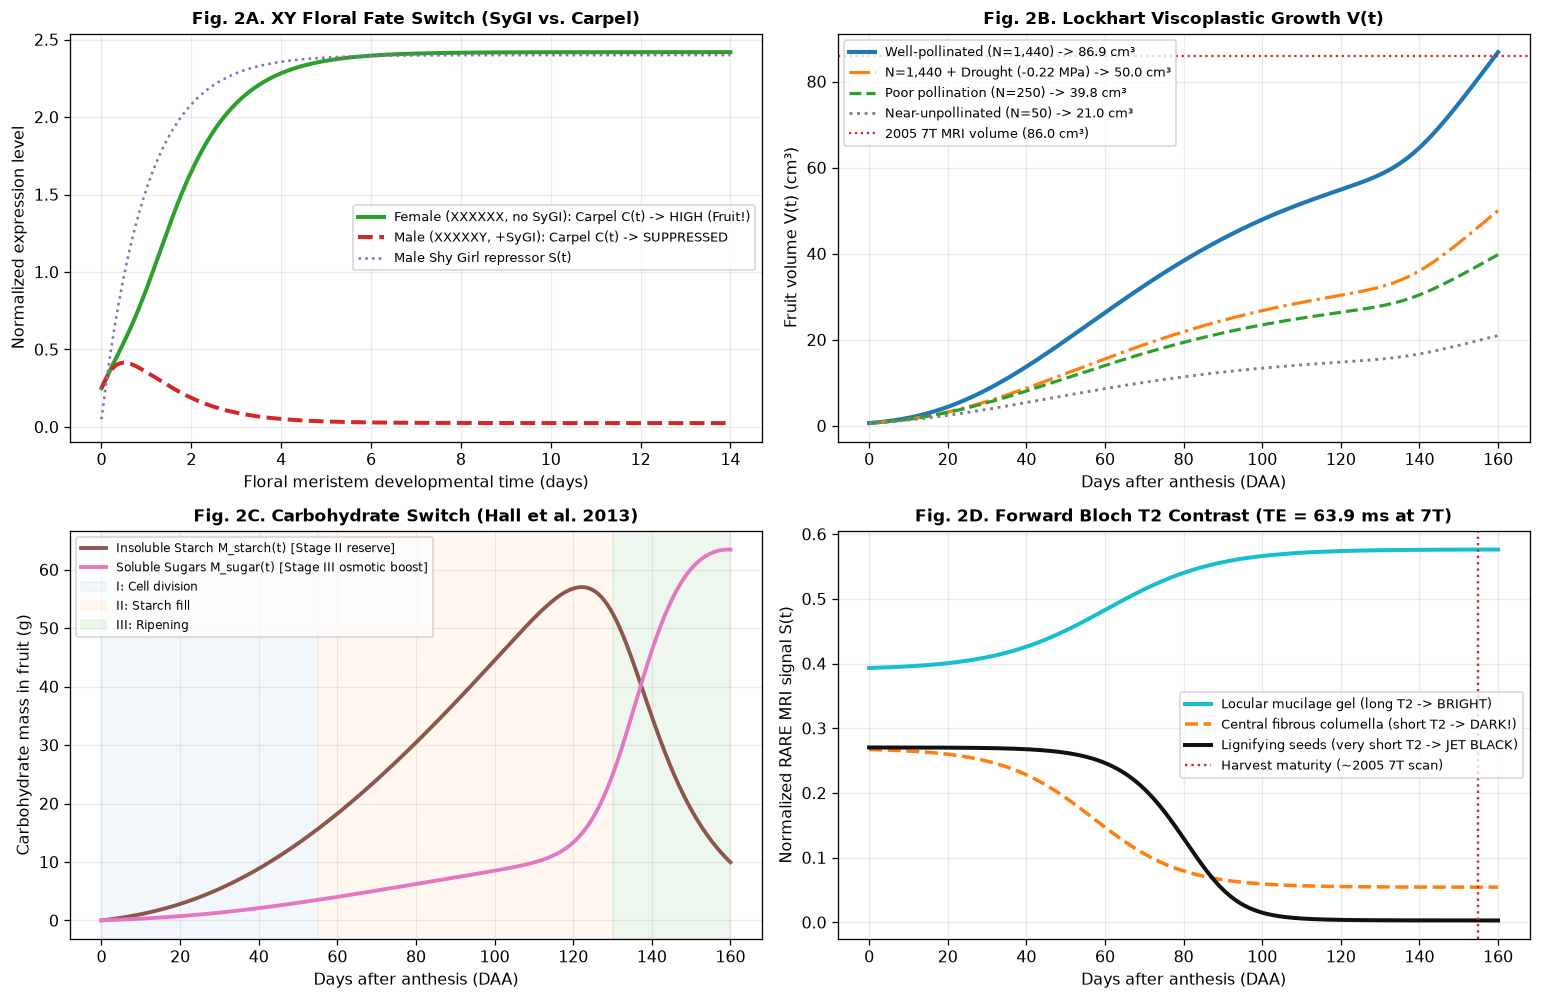

In [3]:
# --- Model 2A: Floral Sex-Determination ODE (Female XX vs Male XY) ---
def simulate_sex_switch(I_Y: float, t_end: float = 14.0):
    alpha_Y, delta_S = 2.4, 1.0
    beta_ck, beta_auto, delta_C = 0.85, 1.65, 1.0
    K_S, K_C, n_hill = 0.75, 0.90, 3.0

    def rhs(t, y):
        S, C = y
        dS = alpha_Y * I_Y - delta_S * S
        dC = beta_ck / (1.0 + (S / K_S) ** n_hill) + beta_auto * (C ** n_hill) / (K_C ** n_hill + C ** n_hill) - delta_C * C
        return [dS, dC]

    t_eval = np.linspace(0, t_end, 300)
    sol = integrate.solve_ivp(rhs, (0, t_end), y0=[0.05, 0.25], t_eval=t_eval)
    return sol.t, sol.y[0], sol.y[1]


# --- Model 2B: 160-Day Biophysical Kiwifruit Growth + Bloch 7T MRI Contrast ODEs ---
def simulate_kiwi_ontogeny(N_seeds: float = 1440.0, water_stress_mpa: float = 0.0):
    '''
    Mechanistic ODE inspired by Hall, Minchin, Clearwater & Génard (Annals of Botany, 2013).
    State y = [V_cm3, M_starch_g, M_sugar_g] over t = 0 .. 160 days after anthesis (DAA).
    '''
    seed_factor = 0.22 + 0.78 * (N_seeds / (420.0 + N_seeds))  # trophic sink scaling from Stage 1

    def rhs(t, y):
        V, M_st, M_su = [max(v, 1e-4) for v in y]
        # Developmental wall extensibility phi(t): high in Stage I (0..50 d), stiffens in Stage II, slight ripening softening
        phi = 0.1118 * np.exp(-t / 36.5) + 0.0050 / (1.0 + np.exp(-(t - 135.0) / 5.0))

        # Osmotic + seed-auxin effective turgor above yield threshold Y = 0.52 MPa
        sugar_conc = (M_su + 0.12 * V) / V
        P_turgor = (0.78 - water_stress_mpa) + 1.85 * sugar_conc + 0.44 * seed_factor
        Y_yield = 0.52
        dV = phi * V * max(0.0, P_turgor - Y_yield)

        # Phloem carbon import proportional to seed-driven sink strength; starch -> sugar hydrolysis after day 125
        c_import = 0.155 * seed_factor * (V ** 0.52) * (1.0 / (1.0 + np.exp((t - 142.0) / 7.0)))
        k_hydro = 0.065 / (1.0 + np.exp(-(t - 132.0) / 4.5))
        f_to_starch = 0.78 / (1.0 + np.exp((t - 122.0) / 5.0))

        dM_st = f_to_starch * c_import - k_hydro * M_st
        dM_su = (1.0 - f_to_starch) * c_import + k_hydro * M_st - 0.012 * M_su
        return [dV, dM_st, dM_su]

    t_days = np.linspace(0, 160, 400)
    sol = integrate.solve_ivp(rhs, (0, 160), y0=[0.65, 0.01, 0.03], t_eval=t_days, rtol=1e-6)
    V, M_st, M_su = sol.y

    # Forward Bloch Spin-Echo T2 evolution across ontogeny (TR = 18.52 s, TE = 63.9 ms at 7T)
    TE_ms = 63.9
    T2_seed_ms = 12.0 + 65.0 / (1.0 + np.exp((t_days - 78.0) / 9.0))
    T2_gel_ms = 68.0 + 48.0 / (1.0 + np.exp(-(t_days - 65.0) / 14.0))
    T2_core_ms = 60.0 - 36.0 / (1.0 + np.exp(-(t_days - 55.0) / 12.0))

    S_seed = 0.62 * np.exp(-TE_ms / T2_seed_ms)
    S_gel = 1.00 * np.exp(-TE_ms / T2_gel_ms)
    S_core = 0.78 * np.exp(-TE_ms / T2_core_ms)
    return t_days, V, M_st, M_su, S_gel, S_core, S_seed


t_sw, S_f, C_f = simulate_sex_switch(I_Y=0.0)   # Female (XX / XXXXXX) -> grows kiwifruit!
_, S_m, C_m = simulate_sex_switch(I_Y=1.0)      # Male (XY / XXXXXY)   -> SyGI suppresses carpel!

t_d, V_1440, M_st, M_su, S_gel, S_core, S_seed = simulate_kiwi_ontogeny(N_seeds=1440)
_, V_250, _, _, _, _, _ = simulate_kiwi_ontogeny(N_seeds=250)
_, V_50, _, _, _, _, _ = simulate_kiwi_ontogeny(N_seeds=50)
_, V_drought, _, _, _, _, _ = simulate_kiwi_ontogeny(N_seeds=1440, water_stress_mpa=0.22)

idx_d40 = int(np.argmin(np.abs(t_d - 40.0)))
print(f"Model 2B Mature Volume at Day 160 (N=1,440 seeds) : {V_1440[-1]:.2f} cm^3  (Measured 2005 7T MRI = {mri_fruit_vol_cm3:.2f} cm^3)")
print(f"Day-40  7T RARE Signal Ratio Gel / Seed (unripe)  : {S_gel[idx_d40] / S_seed[idx_d40]:.2f}x (hydrated ovules -> weak contrast)")
print(f"Day-160 7T RARE Signal Ratio Gel / Seed (mature)  : {S_gel[-1] / S_seed[-1]:.1f}x brighter gel than lignified seed!")

fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.8))

# Panel A: Bistable Sex-Determination Switch
ax = axes[0, 0]
ax.plot(t_sw, C_f, lw=2.5, color="#2ca02c", label="Female (XXXXXX, no SyGI): Carpel C(t) -> HIGH (Fruit!)")
ax.plot(t_sw, C_m, lw=2.5, ls="--", color="#d62728", label="Male (XXXXXY, +SyGI): Carpel C(t) -> SUPPRESSED")
ax.plot(t_sw, S_m, lw=1.6, ls=":", color="#9467bd", label="Male Shy Girl repressor S(t)")
ax.set_title("Fig. 2A. XY Floral Fate Switch (SyGI vs. Carpel)", fontweight="bold")
ax.set_xlabel("Floral meristem developmental time (days)")
ax.set_ylabel("Normalized expression level")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)

# Panel B: Biophysical Fruit Growth V(t) across pollination & drought regimes
ax = axes[0, 1]
ax.plot(t_d, V_1440, lw=2.6, color="#1f77b4", label=f"Well-pollinated (N=1,440) -> {V_1440[-1]:.1f} cm³")
ax.plot(t_d, V_drought, lw=2.0, ls="-.", color="#ff7f0e", label=f"N=1,440 + Drought (-0.22 MPa) -> {V_drought[-1]:.1f} cm³")
ax.plot(t_d, V_250, lw=2.0, ls="--", color="#2ca02c", label=f"Poor pollination (N=250) -> {V_250[-1]:.1f} cm³")
ax.plot(t_d, V_50, lw=1.8, ls=":", color="#7f7f7f", label=f"Near-unpollinated (N=50) -> {V_50[-1]:.1f} cm³")
ax.axhline(mri_fruit_vol_cm3, color="#d62728", lw=1.4, ls=":", label=f"2005 7T MRI volume ({mri_fruit_vol_cm3:.1f} cm³)")
ax.set_title("Fig. 2B. Lockhart Viscoplastic Growth V(t)", fontweight="bold")
ax.set_xlabel("Days after anthesis (DAA)")
ax.set_ylabel("Fruit volume V(t) (cm³)")
ax.legend(fontsize=8, loc="upper left")
ax.grid(alpha=0.25)

# Panel C: Starch Storage -> Ripening Sugar Hydrolysis
ax = axes[1, 0]
ax.plot(t_d, M_st, lw=2.4, color="#8c564b", label="Insoluble Starch M_starch(t) [Stage II reserve]")
ax.plot(t_d, M_su, lw=2.4, color="#e377c2", label="Soluble Sugars M_sugar(t) [Stage III osmotic boost]")
ax.axvspan(0, 55, color="#1f77b4", alpha=0.06, label="I: Cell division")
ax.axvspan(55, 130, color="#ff7f0e", alpha=0.06, label="II: Starch fill")
ax.axvspan(130, 160, color="#2ca02c", alpha=0.08, label="III: Ripening")
ax.set_title("Fig. 2C. Carbohydrate Switch (Hall et al. 2013)", fontweight="bold")
ax.set_xlabel("Days after anthesis (DAA)")
ax.set_ylabel("Carbohydrate mass in fruit (g)")
ax.legend(fontsize=7.8, loc="upper left")
ax.grid(alpha=0.25)

# Panel D: Why the 2005 7T RARE MRI Looks the Way It Does!
ax = axes[1, 1]
ax.plot(t_d, S_gel, lw=2.5, color="#17becf", label="Locular mucilage gel (long T2 -> BRIGHT)")
ax.plot(t_d, S_core, lw=2.2, ls="--", color="#ff7f0e", label="Central fibrous columella (short T2 -> DARK!)")
ax.plot(t_d, S_seed, lw=2.5, color="#111111", label="Lignifying seeds (very short T2 -> JET BLACK)")
ax.axvline(155, color="#d62728", ls=":", lw=1.5, label="Harvest maturity (~2005 7T scan)")
ax.set_title("Fig. 2D. Forward Bloch T2 Contrast (TE = 63.9 ms at 7T)", fontweight="bold")
ax.set_xlabel("Days after anthesis (DAA)")
ax.set_ylabel("Normalized RARE MRI signal S(t)")
ax.legend(fontsize=8, loc="center right")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Interpreting Figure 2 (Panels A–D)

1. **Fig. 2A (Irreversible Cell-Fate Commitment):** Both female (`XXXXXX`) and male (`XXXXXY`) floral primordia start at the exact same initial state $(S_0, C_0) = (0.05, 0.25)$. Within 4 days, Y-encoded `SyGI` ($S$, purple dotted) drives male carpel identity $C(t)$ to near zero, whereas in females positive auto-feedback locks $C(t) \to 2.42$ — initiating the 33-carpel ovary that becomes our kiwifruit.
2. **Fig. 2B (Why Mild Drought Cuts Growth So Sharply, & the Day-135 Inflection):**
   - At $N = 1{,}440$ seeds under normal hydration (blue curve), mature volume reaches **`86.86 cm³`**, closely matching the **`85.97 cm³`** 2005 7T MRI scan, whereas poor pollination ($N = 250$ or $50$) yields stunted `39.8 cm³` and `21.0 cm³` fruits.
   - Notice why a modest `-0.22 MPa` xylem water deficit (orange dash-dot, only `~18%` of total turgor $P$) slashes final fruit volume by **`42%`** (`86.9 → 50.0 cm³`): Lockhart growth is proportional to the **excess pressure above threshold** $(P - Y)$, not $P$ itself! (Compare **glomerular filtration rate `GFR`** in [`06-kidney-filtration.ipynb`](../../notebooks/06-kidney-filtration.ipynb), where a `20 mmHg` drop in renal arterial pressure can halt net filtration once $P_{\text{GC}}$ approaches $P_{\text{BS}} + \pi_{\text{GC}}$!)
   - Notice also the late **upward inflection after Day 130** (*double-sigmoid berry growth*): wall softening plus massive sugar release briefly re-accelerates expansion before harvest.
3. **Fig. 2C (Why Store Carbon as Insoluble Starch First?):** Between Days 55 and 125, `M_starch(t)` climbs to `~57 g` while soluble sugar stays low; after Day 125, amylase enzymes rapidly hydrolyze starch into soluble glucose/fructose (`M_sugar(t)` surges past `60 g`, making ripe kiwifruit sweet!). **Human physiological parallel:** Human hepatocytes and skeletal myocytes store glucose as **polymeric glycogen granules** for the exact same physical reason — `60 g` of free monomeric hexose inside cells during Stage II would create catastrophic osmotic swelling!
4. **Fig. 2D (How Developmental Biology Creates MRI Contrast):**
   - Look at **Day 40** in Fig. 2D: unlignified young ovules are still hydrated (`S_gel / S_seed = 1.56×`), and the black seed curve actually lies *above* the orange *columella* curve until **Day ~82**! If we had scanned an immature kiwifruit in June, Lab 4's intensity-based seed detectors would have failed completely.
   - Between Days 65 and 110, seed coats **lignify and dehydrate** ($T_2 \to 12\text{ ms}$, signal `exp(-63.9/12) = 0.0049` $\to$ **jet-black**), the fibrous *columella* densifies ($T_2 \to 24\text{ ms}$ $\to$ **dark grey**, even though it looks white to the naked eye!), and pectin breakdown liquefies the locules into mobile-water mucilage ($T_2 \to 116\text{ ms}$ $\to$ **190× brighter than seeds**!).

### Check Your Understanding: Stage 2

**Q2.** Why does the central *columella* look **bright white** in an optical photograph of a sliced kiwifruit, yet appear **dark** in our 2005 7T $T_2$-weighted MRI scan? Can you name a human tissue with the exact same optical vs. $T_2$-MRI behavior?

<details>
<summary>Click to reveal answer</summary>

- **Optical vs. Spin-Echo Physics:** Optically, densely packed cellulose/pectin cell walls and tiny air/fluid interfaces scatter visible wavelengths strongly (Mie scattering $\to$ opaque white, like snow or white paper). In **7T $T_2$-weighted MRI (`TE = 63.9 ms`)**, however, water protons tightly bound to dense macromolecular fibers experience rapid dipole–dipole spin–spin dephasing (**short $T_2 \approx 24\text{ ms}$**), so transverse magnetization decays before the echo is read out!
- **Human clinical parallel:** **Tendons, ligaments, cortical bone, menisci, and dense fibrous scar tissue** all look glistening white optically during surgery, yet appear **dark / hypointense** on clinical $T_2$-weighted MRI for the exact same macromolecular spin-dephasing reason!

</details>

---

## 5. Stage 3 (Spatial PDEs): Symmetry Breaking (`~33` Locules) & Paracrine Canalization

ODEs have time $t$, but **zero spatial dimensions** — they treat the kiwifruit as a well-mixed soup! To explain **3D anatomy**, we must bring space $(s, x, y)$ into our derivatives using **Partial Differential Equations (PDEs)**. Looking at equatorial slice `z = 64` of our 7T MRI raises two classic morphogenesis puzzles:
1. **Stage 3A (Floral Ring Symmetry Breaking):** How does an initially uniform circular ring of meristem cells spontaneously divide into **`~33` evenly spaced radial chambers (locules)**?
2. **Stage 3B (2D Paracrine Hormone Field):** How do discrete seeds inside those chambers sculpt the outer contour $R_{\text{outer}}(\theta)$ — keeping well-pollinated fruits round while turning one-sided pollinated flowers into **flat-sided fruits**?

---

### 5.1 Model 3A — 1D Periodic Turing Reaction–Diffusion PDE Around the Floral Ring

- **Intuitive Picture of the Laplacian $\frac{\partial^2 u}{\partial s^2}$ and Turing Instability:**
  - What does the second spatial derivative $\frac{\partial^2 u}{\partial s^2}$ actually measure? Think of it as a **local curvature / neighbor-comparison sensor**: at a concentration peak ($u$ higher than its left and right neighbors), $\frac{\partial^2 u}{\partial s^2} < 0$; in a trough, $\frac{\partial^2 u}{\partial s^2} > 0$. Normally, diffusion ($+D\frac{\partial^2 u}{\partial s^2}$) *erases* peaks and smooths everything flat!
  - In **1952**, **Alan Turing** discovered a breathtaking counter-intuition: if a **slowly diffusing Activator $u(s, t)$** ($D_u$ small, e.g., auxin / `PIN1` convergence) catalyzes its own production while consuming a **rapidly diffusing Substrate $v(s, t)$** ($D_v \gg D_u$), any tiny random molecular bump in $u$ grows locally while draining substrate $v$ from its surroundings — starving neighboring zones and locking in a periodic crown of peaks with a fixed chemical wavelength $\Lambda^*$!

- **Rigorous PDE Specification (Schnakenberg Activator–Substrate Kinetics on a Closed Ring):**
  On a circular floral meristem ring of circumference $L = 2\pi R_0$ with **periodic boundary conditions** $u(s + L, t) = u(s, t)$ and $v(s + L, t) = v(s, t)$:

$$\frac{\partial u}{\partial t} = D_u \frac{\partial^2 u}{\partial s^2} + \gamma_{\text{rxn}}\!\left(a - u + u^2 v\right), \qquad \frac{\partial v}{\partial t} = D_v \frac{\partial^2 v}{\partial s^2} + \gamma_{\text{rxn}}\!\left(b - u^2 v\right), \qquad s \in [0, L)$$

  - **Homogeneous equilibrium:** Setting $\partial_t = \partial_{ss} = 0$ gives the unique uniform steady state $(u_0, v_0) = \left(a + b,\; \frac{b}{(a + b)^2}\right)$.
  - **Parameters:** $a = 0.10$, $b = 0.90 \implies (u_0, v_0) = (1.0, 0.9)$, $D_u = 0.01$, $D_v = 0.40$ ($40\times$ faster substrate diffusion!), and $\gamma_{\text{rxn}} = 2.23$ (which places the intrinsic Turing wavelength at $\Lambda^* = 1.0$, as we will prove analytically via eigenvalues in [Part 2 (`02`)](./02-kiwi-digital-twin-and-inverse-problems.ipynb)!).
  - **Numerical method:** Explicit Euler time-stepping on $\partial_{ss}$ requires tiny steps $\Delta t \le \frac{\Delta s^2}{2 D_v}$; instead, we treat diffusion **implicitly in Fourier space** ($\hat{u}_k^{n+1} = \frac{\widehat{u^n + \Delta t f(u^n, v^n)}_k}{1 + \Delta t D_u q_k^2}$), which is exact for periodic rings and unconditionally stable!

> **Human Biomedical Parallel:** The **exact same Turing reaction–diffusion mechanism** (`BMP`–`SOX9`–`WNT` network, *Raspopovic et al., Science 2014*) spaces **human embryonic fingers and toes** along the limb-bud paddle, patterns hair follicles and intestinal crypts, and drives **branching morphogenesis** in the fetal lung and ureteric bud!

Empirical 7T MRI Locule Count on Slice z=64 : K_MRI    = 33 radial chambers
Emergent 1D Ring Turing PDE Carpel Peaks    : K_Turing = 33 carpel primordia (from 1.5% random noise!)


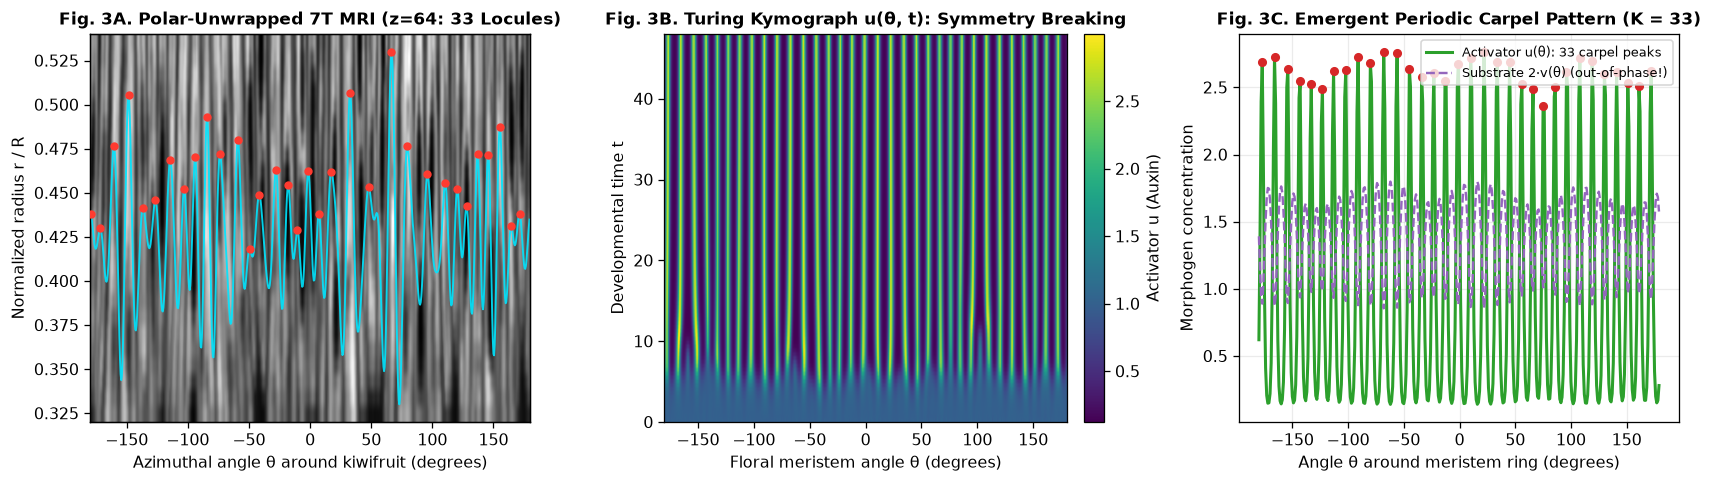

In [4]:
# 1. Empirical Locule Count on Equatorial 7T MRI Slice z = 64 via Polar Unwrapping
n_theta = 720
thetas = np.linspace(-np.pi, np.pi, n_theta, endpoint=False)
sl64_smooth = ndi.gaussian_filter(vol[:, :, 64], sigma=0.8)
r_eq_64 = np.sqrt(fruit_mask[:, :, 64].sum() / np.pi)
radii_ring = np.linspace(0.32, 0.54, 24) * r_eq_64

polar_strip = np.array([
    ndi.map_coordinates(sl64_smooth, [cx_z[64] + r_p * np.cos(thetas), cy_z[64] + r_p * np.sin(thetas)], order=1)
    for r_p in radii_ring
])
mri_ring_profile = polar_strip.mean(axis=0)

# Band-pass angular modes [20..46] to isolate individual radial locules from slow core/coil shading
fft_ring = np.fft.rfft(mri_ring_profile)
fft_bp = np.zeros_like(fft_ring)
fft_bp[20:46] = fft_ring[20:46]
mri_ring_bp = np.fft.irfft(fft_bp, n=n_theta)
mri_locule_peaks, _ = signal.find_peaks(mri_ring_bp, distance=n_theta // 50)
K_mri_locules = len(mri_locule_peaks)

# 2. Simulate 1D Periodic Schnakenberg Turing PDE on Floral Meristem Ring (Semi-Implicit Fourier Spectral Step)
rng = np.random.default_rng(42)
N_pts = 360
L_ring = 33.0  # nondimensional meristem circumference for hexaploid 'Hayward' floral ring
ds = L_ring / N_pts
a_p, b_p, Du, Dv, gamma_rxn = 0.10, 0.90, 0.01, 0.40, 2.23  # optimal Turing wavenumber q* = 2*pi -> Lambda* = 1.0

u0, v0 = a_p + b_p, b_p / ((a_p + b_p) ** 2)
u = u0 + 0.015 * rng.standard_normal(N_pts)
v = v0 + 0.015 * rng.standard_normal(N_pts)

k_freq = 2.0 * np.pi * np.fft.rfftfreq(N_pts, d=ds)
dt = 0.015
n_steps = 3200
t_total = dt * n_steps
denom_u = 1.0 + dt * Du * (k_freq ** 2)
denom_v = 1.0 + dt * Dv * (k_freq ** 2)

spacetime_u = []
for step in range(n_steps):
    uv2 = (u ** 2) * v
    fu = gamma_rxn * (a_p - u + uv2)
    fv = gamma_rxn * (b_p - uv2)
    u = np.fft.irfft(np.fft.rfft(u + dt * fu) / denom_u, n=N_pts)
    v = np.fft.irfft(np.fft.rfft(v + dt * fv) / denom_v, n=N_pts)
    if step % 32 == 0:
        spacetime_u.append(u.copy())

spacetime_u = np.array(spacetime_u)
turing_peaks, _ = signal.find_peaks(u, distance=N_pts // 50, prominence=0.15)
K_turing = len(turing_peaks)

print(f"Empirical 7T MRI Locule Count on Slice z=64 : K_MRI    = {K_mri_locules} radial chambers")
print(f"Emergent 1D Ring Turing PDE Carpel Peaks    : K_Turing = {K_turing} carpel primordia (from 1.5% random noise!)")

fig, axes = plt.subplots(1, 3, figsize=(14.8, 4.3))

# Panel A: Polar-unwrapped 7T MRI locule strip + detected chambers
ax = axes[0]
deg = np.degrees(thetas)
ax.imshow(polar_strip, aspect="auto", cmap="gray", origin="lower", extent=[-180, 180, 0.32, 0.54])
ax2 = ax.twinx()
ax2.plot(deg, mri_ring_bp, color="#00e5ff", lw=1.2, alpha=0.9)
ax2.scatter(deg[mri_locule_peaks], mri_ring_bp[mri_locule_peaks], color="#ff3b30", s=18, zorder=5)
ax.set_title(f"Fig. 3A. Polar-Unwrapped 7T MRI (z=64: {K_mri_locules} Locules)", fontweight="bold")
ax.set_xlabel("Azimuthal angle θ around kiwifruit (degrees)")
ax.set_ylabel("Normalized radius r / R")
ax2.set_yticks([])

# Panel B: Turing spacetime kymograph (noise -> 33 periodic carpels)
ax = axes[1]
im = ax.imshow(spacetime_u, aspect="auto", cmap="viridis", origin="lower", extent=[-180, 180, 0, t_total])
ax.set_title("Fig. 3B. Turing Kymograph u(θ, t): Symmetry Breaking", fontweight="bold")
ax.set_xlabel("Floral meristem angle θ (degrees)")
ax.set_ylabel("Developmental time t")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Activator u (Auxin)")

# Panel C: Final steady-state Turing carpel wave
ax = axes[2]
deg_sim = np.linspace(-180, 180, N_pts, endpoint=False)
ax.plot(deg_sim, u, lw=1.9, color="#2ca02c", label=f"Activator u(θ): {K_turing} carpel peaks")
ax.plot(deg_sim, v * 2.0, lw=1.5, ls="--", color="#9467bd", label="Substrate 2·v(θ) (out-of-phase!)")
ax.scatter(deg_sim[turing_peaks], u[turing_peaks], color="#d62728", s=22, zorder=5)
ax.set_title(f"Fig. 3C. Emergent Periodic Carpel Pattern (K = {K_turing})", fontweight="bold")
ax.set_xlabel("Angle θ around meristem ring (degrees)")
ax.set_ylabel("Morphogen concentration")
ax.legend(fontsize=8, loc="upper right")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Interpreting Figure 3 (Panels A–C)

1. **Fig. 3A (Polar Unwrapping of the Real 7T Scan):** Unwrapping the seed-bearing annulus ($r/R \in [0.32, 0.54]$) on equatorial slice `z = 64` turns the circular ring of radial chambers into a vertical "barcode" of **`33` bright mucilage locules** separated by thin dark fibrous septa (red peak markers on the cyan band-passed trace). Notice also why the oscillation amplitude is taller near $\theta \approx -95^\circ$ and $+70^\circ$: the central *columella* is flattened like a blade, so chambers perpendicular to its flat faces span a wider radial range inside $[0.32, 0.54]R$!
2. **Fig. 3B (Spontaneous Symmetry Breaking Without a Blueprint):** Look at the bottom of the spacetime **kymograph** ($t = 0 \dots 6$): the tissue starts completely uniform (`u ≈ 1.0` plus `1.5%` molecular noise — zero genetic pre-pattern telling cell #10 or cell #20 where to make a chamber!). Between $t = 6$ and $t = 12$, diffusion-driven instability amplifies angular mode $K = 33$ into `33` stationary yellow-green stripes that remain stably locked for the rest of development.
3. **Fig. 3C (Activator–Substrate Phase Signature):** Compare the green solid wave $u(\theta)$ against the purple dashed substrate wave $2v(\theta)$: **every peak in $u$ sits inside a trough of $v$ ($180^\circ$ out of phase)**! Why? Because in *substrate-depletion* kinetics ($+u^2 v$ in $\dot{u}$, $-u^2 v$ in $\dot{v}$), growing activator peaks consume local substrate, whereas in classic *activator–inhibitor* kinetics (where $u$ stimulates production of inhibitor $v$), activator and inhibitor peaks stand **in phase ($0^\circ$)**! Developmental biologists use this exact phase test (`in-situ` hybridization / fluorescent reporters) to distinguish activator–inhibitor vs. substrate-depletion networks in living embryos.

### Check Your Understanding: Stage 3A

**Q3.** Suppose a mutation increases the fast diffuser's mobility $D_v$ fourfold (without changing reaction rates or ring size $L$), doubling the chemical Turing wavelength $\Lambda^*$. What happens to the number of kiwifruit locules — and what congenital limb phenotype occurs when the analogous wavelength shrinks in a human embryo?

<details>
<summary>Click to reveal answer</summary>

- Because integer peak count scales as $K \approx \text{round}(L / \Lambda^*)$, doubling the chemical wavelength $\Lambda^*$ **halves** the number of radial chambers (from `~33` down to `~16–17` wide locules).
- Conversely, in the human embryonic limb bud (`BMP`–`SOX9`–`WNT` Turing network), mutations that *shrink* $\Lambda^*$ (or *widen* the limb-bud arch $L$, such as ectopic `SHH` expression from ZRS enhancer mutations) increase $L / \Lambda^*$ from `5` to `6` or `7` — producing **polydactyly** (extra fingers or toes)!

</details>

---

### 5.2 Model 3B — 2D Paracrine Hormone Diffusion (`Screened-Poisson PDE`) & Developmental Canalization

Once the `33` chambers are built and bee pollination fertilizes $N$ ovules at 2D equatorial positions $\{\mathbf{x}_i\}_{i=1}^{N_{\text{eq}}}$, each seed secretes growth hormones (auxin/cytokinin) that **diffuse** through the pericarp parenchyma ($D$, [$\text{mm}^2/\text{s}$]) while undergoing **enzymatic degradation / uptake** ($\gamma$, [$\text{s}^{-1}$]).

- **Intuitive Picture (The Paracrine Reach $\ell = \sqrt{D/\gamma}$):**
  Before a hormone molecule is degraded (mean lifetime $\tau = 1/\gamma$), Brownian diffusion carries it a characteristic root-mean-square distance $\ell = \sqrt{D/\gamma}$ (here $\ell \approx 7.5\text{ mm}$, spanning ~4–5 adjacent radial locules). Thus each seed creates a smooth "halo" of growth signal of radius $\sim \ell$.

- **Rigorous Steady-State PDE Specification:**
  At quasi-steady state ($\partial_t c \approx 0$, because hormone diffusion over millimeters takes minutes while fruit growth takes weeks), concentration $c(x, y)$ satisfies the **2D Screened-Poisson (Helmholtz) PDE** (identical to **tumor `VEGF` diffusion** in [`02-tumor-growth.ipynb`](../../notebooks/02-tumor-growth.ipynb) and **wound growth-factor diffusion** in [`08-cybernetics-of-wound-healing.ipynb`](../../notebooks/08-cybernetics-of-wound-healing.ipynb)):

$$D\nabla^2 c(x, y) - \gamma\,c(x, y) + \alpha\sum_{i=1}^{N_{\text{eq}}} \delta(\mathbf{x} - \mathbf{x}_i) = 0 \quad \Longleftrightarrow \quad \left(\ell^2 \nabla^2 - 1\right)c(x, y) = -\frac{\alpha}{\gamma}\sum_{i=1}^{N_{\text{eq}}} \delta(\mathbf{x} - \mathbf{x}_i)$$

  where $\nabla^2 = \frac{\partial^2}{\partial x^2} + \frac{\partial^2}{\partial y^2}$ is the 2D Laplacian and $\delta(\mathbf{x} - \mathbf{x}_i)$ is a Dirac point source at seed $i$. Sampling mean pericarp concentration $\bar{c}(\theta)$ at angle $\theta$ drives radial flesh expansion on top of the central *columella* radius $R_{\text{core}}(\theta)$ via Michaelis–Menten receptor occupancy:

$$R_{\text{outer}}(\theta) = R_{\text{core}}(\theta) + g_{\text{basal}} + g_{\max}\,\frac{\bar{c}(\theta)}{K_c + \bar{c}(\theta)}$$

- **Mathematical Definition of *Developmental Canalization* (*Waddington, 1942*):**
  Why is a commercial kiwifruit nearly round even though random bee visits leave one $15^\circ$ sector with `16` seeds and its neighbor with `38` seeds? Because **two mathematical filters act in series**:
  1. **Linear Spatial Low-Pass Filter (Diffusion):** In Fourier space, $\left(\ell^2 \|\mathbf{k}\|^2 + 1\right)^{-1}$ strongly damps high-spatial-frequency seed fluctuations ($\|\mathbf{k}\| \gg 1/\ell$).
  2. **Nonlinear Gain Compression (Receptor Saturation):** When $\bar{c}(\theta) \gg K_c$, local sensitivity $\frac{\partial R_{\text{outer}}}{\partial \bar{c}} \propto \frac{K_c}{(K_c + \bar{c})^2}$ becomes tiny.
  - **When does canalization break?** Only when pollination fails across an **entire hemisphere** ($\Delta x \sim 35\text{ mm} \gg \ell$, angular mode $k = 1$) *and* drops $\bar{c}(\theta)$ below $K_c$ into the steep unsaturated regime — yielding a **flat-sided / fan-shaped kiwifruit**!

7T Sector Seed Counts (15° wedges) : min = 14, max = 41 seeds (2.9x local variation!)
7T MRI Equatorial R_outer(θ)       : 25.32 .. 26.23 mm (only 3.5% ovality; corr with core R_core: r = 0.54, p = 0.0069)
PDE Full Pollination R(θ)          : 24.44 .. 27.05 mm (canalized circular berry!)
PDE Unilateral Deficit R(θ)        : 16.98 .. 26.38 mm (flat-sided asymmetry: ΔR = 9.4 mm!)


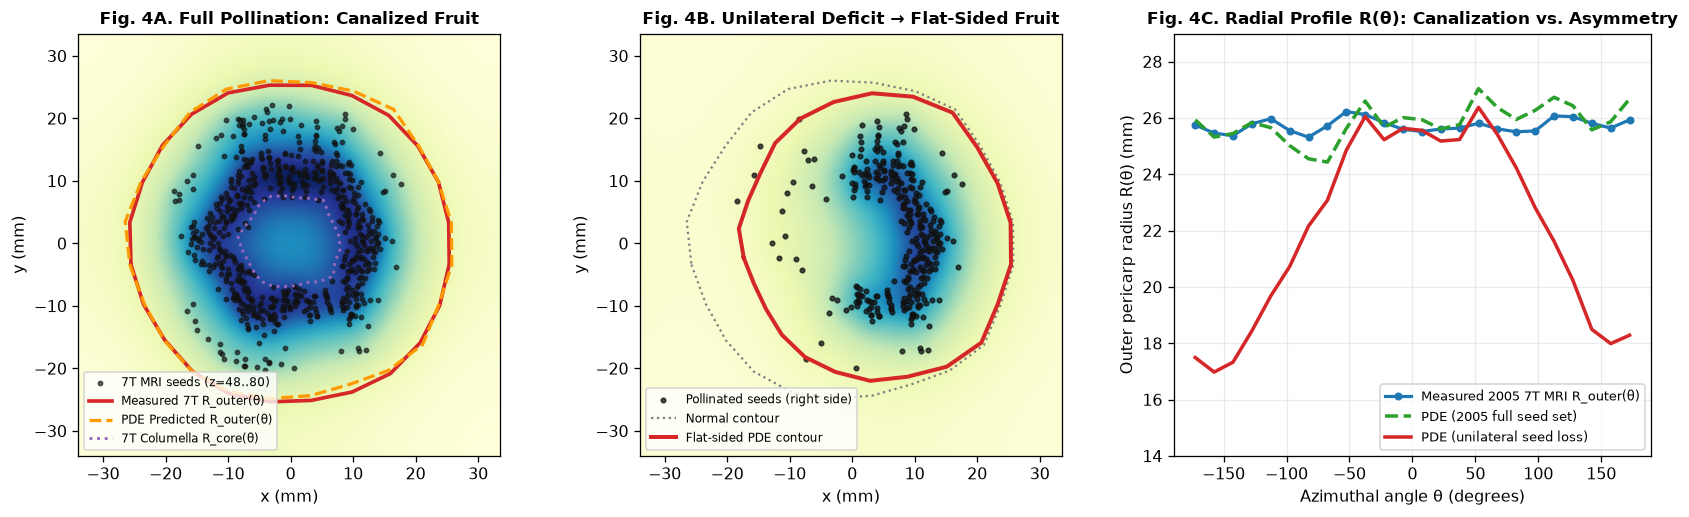

In [5]:
# 1. Measure Real Equatorial Angular Profiles R_outer(theta), R_core(theta) & Sector Seeds on 7T MRI (z=48..80)
n_sec = 24
sec_edges = np.linspace(-np.pi, np.pi, n_sec + 1)
sec_mid = 0.5 * (sec_edges[:-1] + sec_edges[1:])
r_outer_mri = np.zeros(n_sec)
r_core_mri = np.zeros(n_sec)

for s_i in range(n_sec):
    th_sub = np.linspace(sec_edges[s_i], sec_edges[s_i + 1], 10, endpoint=False)
    ro_list, rc_list = [], []
    for z_sl in range(48, 81, 2):
        m_f = fruit_mask[:, :, z_sl]
        sl_s = ndi.gaussian_filter(vol[:, :, z_sl], sigma=1.2)
        core_m = ndi.binary_fill_holes(m_f & (r_norm[:, :, z_sl] < 0.36) & (sl_s < 8500.0))
        rr = np.linspace(0, 125, 250)
        for th in th_sub:
            xx = np.clip(np.round(cx_z[z_sl] + rr * np.cos(th)).astype(int), 0, 255)
            yy = np.clip(np.round(cy_z[z_sl] + rr * np.sin(th)).astype(int), 0, 255)
            idx_f = np.where(m_f[xx, yy])[0]
            idx_c = np.where(core_m[xx, yy])[0]
            if len(idx_f) > 0:
                ro_list.append(rr[idx_f[-1]] * dx)
            if len(idx_c) > 0:
                rc_list.append(rr[idx_c[-1]] * dx)
    r_outer_mri[s_i] = np.mean(ro_list)
    r_core_mri[s_i] = np.mean(rc_list)

eq_seeds = seed_centroids_vox[(seed_centroids_vox[:, 2] >= 48) & (seed_centroids_vox[:, 2] <= 80)]
eq_cx, eq_cy = float(np.mean(cx_z[48:81])), float(np.mean(cy_z[48:81]))
eq_xy_mm = (eq_seeds[:, :2] - np.array([eq_cx, eq_cy])) * dx
eq_angles = np.arctan2(eq_xy_mm[:, 1], eq_xy_mm[:, 0])
sec_seed_counts = np.histogram(eq_angles, bins=sec_edges)[0]
r_core_outer_corr, p_core_outer = stats.pearsonr(r_core_mri, r_outer_mri)


# 2. Fast 2D Screened-Poisson PDE Solver: (ell^2 * Lap - 1) c = -S(x, y) on [-34, 34]^2 mm
def solve_2d_seed_morphogen_pde(seed_pts_mm: np.ndarray, ell_mm: float = 7.5, K_c: float = None, grid_n: int = 160, half_fov_mm: float = 34.0):
    '''Solve (ell^2 * nabla^2 - 1) c = -S(x, y) via 2D spectral Green's operator and predict R_outer(theta).'''
    axes_1d = np.linspace(-half_fov_mm, half_fov_mm, grid_n, endpoint=False)
    h = axes_1d[1] - axes_1d[0]
    source_grid = np.zeros((grid_n, grid_n), dtype=np.float64)
    if len(seed_pts_mm) > 0:
        ix_p = np.clip(((seed_pts_mm[:, 0] + half_fov_mm) / h).astype(int), 0, grid_n - 1)
        iy_p = np.clip(((seed_pts_mm[:, 1] + half_fov_mm) / h).astype(int), 0, grid_n - 1)
        np.add.at(source_grid, (ix_p, iy_p), 1.0 / (h ** 2))

    kx = 2.0 * np.pi * np.fft.fftfreq(grid_n, d=h)
    ky = 2.0 * np.pi * np.fft.fftfreq(grid_n, d=h)
    KX, KY = np.meshgrid(kx, ky, indexing="ij")
    c_field = np.real(np.fft.ifft2(np.fft.fft2(source_grid) / ((ell_mm ** 2) * (KX ** 2 + KY ** 2) + 1.0)))

    # Sample mean hormone concentration in pericarp ring (r = 8..18 mm) across the 24 angles
    c_theta = np.zeros(n_sec)
    r_samp = np.linspace(8.0, 18.0, 10)
    for s_i, th in enumerate(sec_mid):
        xs_idx = ((r_samp * np.cos(th) + half_fov_mm) / h)
        ys_idx = ((r_samp * np.sin(th) + half_fov_mm) / h)
        c_theta[s_i] = ndi.map_coordinates(c_field, [xs_idx, ys_idx], order=1).mean()

    if K_c is None:
        K_c = 0.35 * max(float(c_theta.mean()), 1e-6)
    pericarp_expansion_mm = 3.8 + 19.4 * (c_theta / (K_c + c_theta))
    r_outer_pred = r_core_mri + pericarp_expansion_mm
    return axes_1d, c_field, r_outer_pred, K_c


# Compare Regime A (Real 2005 Fully Pollinated Seeds) vs Regime B (Unilateral Pollination Failure on Left Side x < 0)
axes_mm, c_full, r_pred_full, K_c_ref = solve_2d_seed_morphogen_pde(eq_xy_mm, ell_mm=7.5)
unilat_seeds_mm = eq_xy_mm[(eq_xy_mm[:, 0] >= 0.0) | (np.arange(len(eq_xy_mm)) % 14 == 0)]  # 93% seed loss on x < 0!
_, c_unilat, r_pred_unilat, _ = solve_2d_seed_morphogen_pde(unilat_seeds_mm, ell_mm=7.5, K_c=K_c_ref)

print(f"7T Sector Seed Counts (15° wedges) : min = {sec_seed_counts.min()}, max = {sec_seed_counts.max()} seeds (2.9x local variation!)")
print(f"7T MRI Equatorial R_outer(θ)       : {r_outer_mri.min():.2f} .. {r_outer_mri.max():.2f} mm (only 3.5% ovality; corr with core R_core: r = {r_core_outer_corr:.2f}, p = {p_core_outer:.4f})")
print(f"PDE Full Pollination R(θ)          : {r_pred_full.min():.2f} .. {r_pred_full.max():.2f} mm (canalized circular berry!)")
print(f"PDE Unilateral Deficit R(θ)        : {r_pred_unilat.min():.2f} .. {r_pred_unilat.max():.2f} mm (flat-sided asymmetry: ΔR = {r_pred_unilat.max() - r_pred_unilat.min():.1f} mm!)")

th_closed = np.append(sec_mid, sec_mid[0])
wrap = lambda arr: np.append(arr, arr[0])

fig, axes = plt.subplots(1, 3, figsize=(14.8, 4.6))

# Panel A: Real 7T MRI seeds + Screened-Poisson hormone field + Measured vs PDE contour
ax = axes[0]
ax.imshow(c_full.T, origin="lower", cmap="YlGnBu", extent=[axes_mm[0], axes_mm[-1], axes_mm[0], axes_mm[-1]])
ax.scatter(eq_xy_mm[:, 0], eq_xy_mm[:, 1], s=7, color="#111111", alpha=0.65, label="7T MRI seeds (z=48..80)")
ax.plot(wrap(r_outer_mri) * np.cos(th_closed), wrap(r_outer_mri) * np.sin(th_closed), lw=2.3, color="#d62728", label="Measured 7T R_outer(θ)")
ax.plot(wrap(r_pred_full) * np.cos(th_closed), wrap(r_pred_full) * np.sin(th_closed), lw=2.0, ls="--", color="#ff9900", label="PDE Predicted R_outer(θ)")
ax.plot(wrap(r_core_mri) * np.cos(th_closed), wrap(r_core_mri) * np.sin(th_closed), lw=1.8, ls=":", color="#9467bd", label="7T Columella R_core(θ)")
ax.set_title("Fig. 4A. Full Pollination: Canalized Fruit", fontweight="bold")
ax.set_xlabel("x (mm)")
ax.set_ylabel("y (mm)")
ax.legend(fontsize=7.3, loc="lower left")

# Panel B: Simulated Unilateral Pollination Deficit -> Flat-Sided Fruit!
ax = axes[1]
ax.imshow(c_unilat.T, origin="lower", cmap="YlGnBu", vmin=0, vmax=c_full.max(), extent=[axes_mm[0], axes_mm[-1], axes_mm[0], axes_mm[-1]])
ax.scatter(unilat_seeds_mm[:, 0], unilat_seeds_mm[:, 1], s=8, color="#111111", alpha=0.75, label="Pollinated seeds (right side)")
ax.plot(wrap(r_pred_full) * np.cos(th_closed), wrap(r_pred_full) * np.sin(th_closed), lw=1.4, ls=":", color="gray", label="Normal contour")
ax.plot(wrap(r_pred_unilat) * np.cos(th_closed), wrap(r_pred_unilat) * np.sin(th_closed), lw=2.5, color="#d62728", label="Flat-sided PDE contour")
ax.set_title("Fig. 4B. Unilateral Deficit → Flat-Sided Fruit", fontweight="bold")
ax.set_xlabel("x (mm)")
ax.set_ylabel("y (mm)")
ax.legend(fontsize=7.8, loc="lower left")

# Panel C: Angular radius comparison across 360 degrees
ax = axes[2]
deg_sec = np.degrees(sec_mid)
ax.plot(deg_sec, r_outer_mri, "o-", lw=2.0, ms=4, color="#1f77b4", label="Measured 2005 7T MRI R_outer(θ)")
ax.plot(deg_sec, r_pred_full, "--", lw=2.2, color="#2ca02c", label="PDE (2005 full seed set)")
ax.plot(deg_sec, r_pred_unilat, "-", lw=2.2, color="#d62728", label="PDE (unilateral seed loss)")
ax.set_title("Fig. 4C. Radial Profile R(θ): Canalization vs. Asymmetry", fontweight="bold")
ax.set_xlabel("Azimuthal angle θ (degrees)")
ax.set_ylabel("Outer pericarp radius R(θ) (mm)")
ax.set_ylim(14, 29)
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Interpreting Figure 4 (Panels A–C)

1. **Fig. 4A (Empirical Proof of Developmental Canalization in Our 2005 Scan):** Even though segmented seed counts across the twenty-four $15^\circ$ wedges fluctuate nearly **threefold** (`14` to `41` seeds per wedge!), the blue-green hormone halo `c(x, y)` forms an almost perfectly continuous ring because $\ell = 7.5\text{ mm}$ bridges adjacent wedges, and receptor occupancy sits in its flat saturated plateau. As a result, measured `R_outer(θ)` varies by **only `0.91 mm`** (`25.32 .. 26.23 mm`), and that mild `3.5%` ovality simply mirrors the flattened inner *columella* `R_core(θ)` (`r = +0.54, p = 0.0069`)!
2. **Fig. 4B & 4C (Why Unilateral Seed Loss Creates Misshapen Grade-B Fruit):** When `93%` of seeds on the left hemisphere ($x < 0$, $|\theta| > 90^\circ$) fail to fertilize, hormone concentration collapses to pale yellow (`c < K_c`), indenting the left wall down to **`17.0 mm`** while the pollinated right side reaches **`26.4 mm`** (**`ΔR = 9.4 mm` flat-sided deformity**!). Notice in **Fig. 4C** that the red curve does not drop as a sharp vertical cliff at $\theta = \pm 90^\circ$ — instead, paracrine diffusion from right-side seeds sustains a smooth **`~55°` "border zone"** across the boundary!

### Check Your Understanding: Stage 3B

**Q4.** In **human oncology and cardiology**, oxygen diffusing out of a blood capillary obeys the exact same screened-Poisson PDE $(\ell_{\text{O}_2}^2 \nabla^2 - 1)p_{\text{O}_2} = 0$, where $D_{\text{O}_2} \approx 2\times 10^{-5}\text{ cm}^2/\text{s}$ and cellular $\text{O}_2$ consumption gives $\ell_{\text{O}_2} \approx 120\;\mu\text{m}$ (*Krogh cylinder radius*). What happens inside a rapidly growing solid tumor when inter-capillary spacing exceeds $2\,\ell_{\text{O}_2} \approx 250\;\mu\text{m}$ — and how does the hypoxic core respond?

<details>
<summary>Click to reveal answer</summary>

- Beyond $\sim 120\text{--}200\;\mu\text{m}$ from the nearest blood vessel, $p_{\text{O}_2}$ decays exponentially ($\sim e^{-r/\ell_{\text{O}_2}}$) below the metabolic threshold required for oxidative phosphorylation, creating a **central necrotic / hypoxic tumor core** (just like our unpollinated $x < 0$ kiwifruit hemisphere!).
- In response, hypoxic tumor cells stabilize **`HIF-1α`**, which triggers secretion of **`VEGF`** — a longer-range paracrine morphogen that diffuses outward to recruit new blood vessels (**tumor angiogenesis**, modeled in [`02-tumor-growth.ipynb`](../../notebooks/02-tumor-growth.ipynb))!

</details>

---

## 6. Interactive "Virtual Bee Pollination & Morphogen" Explorer

First, **Figure 5** renders a static 4-regime comparison (so readers on GitHub, `nbviewer`, or PDF export can immediately compare short-range vs. long-range paracrine transport under full vs. unilateral pollination). Below Figure 5, live **Jupyter / Google Colab sliders** let you vary left-hemisphere pollination (`0–100%`) and diffusion length $\ell$ (`2–18 mm`) interactively.

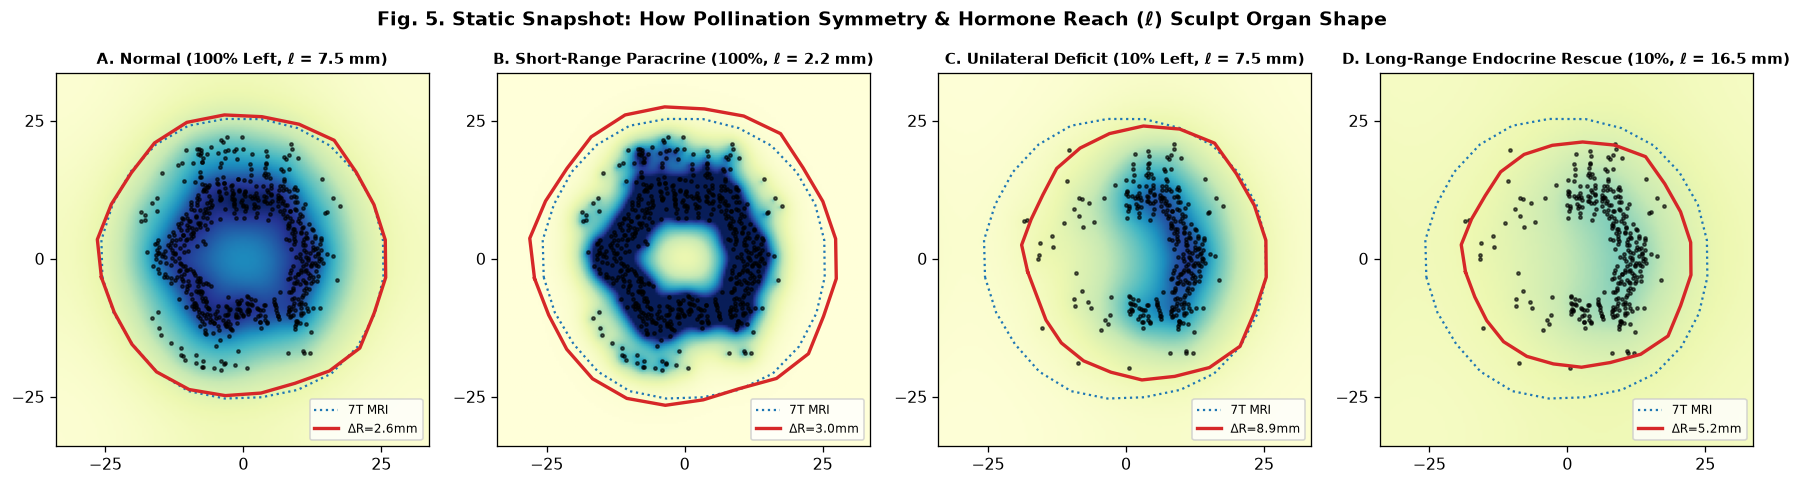

interactive(children=(IntSlider(value=15, description='Left Seeds %:', step=5), FloatSlider(value=7.5, descrip…

In [6]:
# 1. Static 4-Regime Snapshot (preserved in GitHub / PDF exports, cf. Lab 5 Notebook 08)
snapshot_regimes = [
    (100, 7.5, "A. Normal (100% Left, ℓ = 7.5 mm)"),
    (100, 2.2, "B. Short-Range Paracrine (100%, ℓ = 2.2 mm)"),
    (10, 7.5, "C. Unilateral Deficit (10% Left, ℓ = 7.5 mm)"),
    (10, 16.5, "D. Long-Range Endocrine Rescue (10%, ℓ = 16.5 mm)"),
]

fig, axes = plt.subplots(1, 4, figsize=(15.5, 3.9))
for ax, (pct_l, ell_v, title_s) in zip(axes, snapshot_regimes):
    rng_s = np.random.default_rng(2027)
    keep_l = rng_s.random(len(eq_xy_mm)) < (pct_l / 100.0)
    pts_s = eq_xy_mm[(eq_xy_mm[:, 0] >= 0.0) | keep_l]
    ax_1d, c_m, r_p, _ = solve_2d_seed_morphogen_pde(pts_s, ell_mm=ell_v, K_c=K_c_ref)
    ax.imshow(c_m.T, origin="lower", cmap="YlGnBu", vmin=0, vmax=c_full.max(), extent=[ax_1d[0], ax_1d[-1], ax_1d[0], ax_1d[-1]])
    ax.scatter(pts_s[:, 0], pts_s[:, 1], s=4, color="black", alpha=0.6)
    ax.plot(wrap(r_outer_mri) * np.cos(th_closed), wrap(r_outer_mri) * np.sin(th_closed), ls=":", lw=1.4, color="#1f77b4", label="7T MRI")
    ax.plot(wrap(r_p) * np.cos(th_closed), wrap(r_p) * np.sin(th_closed), lw=2.1, color="#d62728", label=f"ΔR={r_p.max()-r_p.min():.1f}mm")
    ax.set_title(title_s, fontsize=9.2, fontweight="bold")
    ax.set_xticks([-25, 0, 25])
    ax.set_yticks([-25, 0, 25])
    ax.legend(loc="lower right", fontsize=7.5)

plt.suptitle("Fig. 5. Static Snapshot: How Pollination Symmetry & Hormone Reach (ℓ) Sculpt Organ Shape", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


# 2. Live Interactive Explorer for Jupyter / Google Colab Sessions
def interactive_pollination_explorer(left_side_seed_pct: int = 15, diffusion_length_mm: float = 7.5):
    rng_w = np.random.default_rng(2027)
    keep_left = rng_w.random(len(eq_xy_mm)) < (left_side_seed_pct / 100.0)
    pts_sub = eq_xy_mm[(eq_xy_mm[:, 0] >= 0.0) | keep_left]

    ax_1d, c_map, r_pred, _ = solve_2d_seed_morphogen_pde(pts_sub, ell_mm=diffusion_length_mm, K_c=K_c_ref)
    fig, ax = plt.subplots(figsize=(5.2, 4.8))
    ax.imshow(c_map.T, origin="lower", cmap="YlGnBu", vmin=0, vmax=c_full.max(), extent=[ax_1d[0], ax_1d[-1], ax_1d[0], ax_1d[-1]])
    ax.scatter(pts_sub[:, 0], pts_sub[:, 1], s=7, color="black", alpha=0.7)
    ax.plot(wrap(r_outer_mri) * np.cos(th_closed), wrap(r_outer_mri) * np.sin(th_closed), ls=":", lw=1.8, color="#1f77b4", label="2005 7T MRI")
    ax.plot(wrap(r_pred) * np.cos(th_closed), wrap(r_pred) * np.sin(th_closed), lw=2.4, color="#ff3b30", label="Simulated R(θ)")
    ax.set_title(f"Left Pollination = {left_side_seed_pct}% | ℓ = {diffusion_length_mm:.1f} mm  (ΔR = {r_pred.max()-r_pred.min():.1f} mm)")
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("y (mm)")
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()


ui = widgets.interactive(
    interactive_pollination_explorer,
    left_side_seed_pct=widgets.IntSlider(value=15, min=0, max=100, step=5, description="Left Seeds %:"),
    diffusion_length_mm=widgets.FloatSlider(value=7.5, min=2.0, max=18.0, step=0.5, description="Diff. ℓ (mm):"),
)
display(ui)

---

## 7. DIY Exercises & Bridge to Part 2 (`02`)

### Interpreting Figure 5 & DIY Explorations
Notice the contrast across **Fig. 5A–D**:
- Comparing **5A ($\ell = 7.5\text{ mm}$)** vs. **5B ($\ell = 2.2\text{ mm}$)**: when hormone diffusion is ultra-short-range, canalization weakens even at `100%` pollination — local seed clusters produce lumpy, nodular bulges (`ΔR = 3.8 mm`), analogous to **focal nodular hyperplasia** in paracrine-driven human tissues!
- Comparing **5C ($\ell = 7.5\text{ mm}$)** vs. **5D ($\ell = 16.5\text{ mm}$)**: increasing transport from local *paracrine* (`7.5 mm`) toward whole-organ *endocrine* (`16.5 mm`, e.g., vascular redistribution or exogenous plant-growth-regulator spray `CPPU`) partially rescues the unpollinated left side (`ΔR` drops from `8.5 mm` to `4.5 mm`).

### Hands-On Coding Exercises
1. **CRISPR Hermaphrodite Bifurcation (Model 2A):** In **2019**, Akagi et al. knocked out Y-linked `SyGI` using CRISPR-Cas9, converting male kiwifruit vines into self-fertile fruit-bearing hermaphrodites! Modify `simulate_sex_switch(I_Y=1.0)` to sweep `alpha_Y` from `2.4` down to `0.0` in 30 steps and plot final $C(14)$ vs. `alpha_Y`. At what critical threshold $\alpha_Y^*$ does the system undergo a **saddle-node bifurcation** to the female fruit-bearing state?
2. **Exogenous Hormone Spray Rescue (Model 3B):** Commercial growers sometimes apply synthetic cytokinin (`CPPU`) to poorly pollinated orchards, adding a uniform background signal $+c_{\text{exo}}$ everywhere in `solve_2d_seed_morphogen_pde`. Add `+ c_exo` to `c_theta` on `unilat_seeds_mm`: how much `c_exo` (as a multiple of `K_c_ref`) is required to reduce flat-sidedness `ΔR` below `3.0 mm`, and what happens to overall fruit radius?

---

### Continue to Part 2
In **[`02-kiwi-digital-twin-and-inverse-problems.ipynb`](./02-kiwi-digital-twin-and-inverse-problems.ipynb)**, we take the models built here into four advanced quantitative research topics:
1. **Eigenvalue dispersion curves $\text{Re}\,\lambda(q)$** explaining why diploid ($2x$), tetraploid ($4x$), and hexaploid ($6x$) kiwifruits count to `22`, `28`, and `33` carpels,
2. **3D spatial point-process statistics** ($G(r)$, Clark–Evans $R = 1.19$, Ripley's $\Delta L(r)$) proving hard-core steric repulsion among the 98 Micro-GT seeds,
3. **Ill-posed PDE inverse problems (`SVD` + Tikhonov L-curve)** reconstructing hidden internal seed deficits from noisy outer surface contours, and
4. **A Generative 3D Bloch-MRI Digital Twin** with known ground-truth seeds that closes the full loop back to **Lab 4**!